# ¡Llena ese carrito!

# Introducción

Instacart es una plataforma de entregas de comestibles donde la clientela puede registrar un pedido y hacer que se lo entreguen, similar a Uber Eats y Door Dash.
El conjunto de datos que te hemos proporcionado tiene modificaciones del original. Redujimos el tamaño del conjunto para que tus cálculos se hicieran más rápido e introdujimos valores ausentes y duplicados. Tuvimos cuidado de conservar las distribuciones de los datos originales cuando hicimos los cambios.

Debes completar tres pasos. Para cada uno de ellos, escribe una breve introducción que refleje con claridad cómo pretendes resolver cada paso, y escribe párrafos explicatorios que justifiquen tus decisiones al tiempo que avanzas en tu solución.  También escribe una conclusión que resuma tus hallazgos y elecciones.


## Diccionario de datos

Hay cinco tablas en el conjunto de datos, y tendrás que usarlas todas para hacer el preprocesamiento de datos y el análisis exploratorio de datos. A continuación se muestra un diccionario de datos que enumera las columnas de cada tabla y describe los datos que contienen.

- `instacart_orders.csv`: cada fila corresponde a un pedido en la aplicación Instacart.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'user_id'`: número de ID que identifica de manera única la cuenta de cada cliente.
    - `'order_number'`: el número de veces que este cliente ha hecho un pedido.
    - `'order_dow'`: día de la semana en que se hizo el pedido (0 si es domingo).
    - `'order_hour_of_day'`: hora del día en que se hizo el pedido.
    - `'days_since_prior_order'`: número de días transcurridos desde que este cliente hizo su pedido anterior.
- `products.csv`: cada fila corresponde a un producto único que pueden comprar los clientes.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'product_name'`: nombre del producto.
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
- `order_products.csv`: cada fila corresponde a un artículo pedido en un pedido.
    - `'order_id'`: número de ID que identifica de manera única cada pedido.
    - `'product_id'`: número ID que identifica de manera única cada producto.
    - `'add_to_cart_order'`: el orden secuencial en el que se añadió cada artículo en el carrito.
    - `'reordered'`: 0 si el cliente nunca ha pedido este producto antes, 1 si lo ha pedido.
- `aisles.csv`
    - `'aisle_id'`: número ID que identifica de manera única cada categoría de pasillo de víveres.
    - `'aisle'`: nombre del pasillo.
- `departments.csv`
    - `'department_id'`: número ID que identifica de manera única cada departamento de víveres.
    - `'department'`: nombre del departamento.

# Paso 1. Descripción de los datos

Lee los archivos de datos (`/datasets/instacart_orders.csv`, `/datasets/products.csv`, `/datasets/aisles.csv`, `/datasets/departments.csv` y `/datasets/order_products.csv`) con `pd.read_csv()` usando los parámetros adecuados para leer los datos correctamente. Verifica la información para cada DataFrame creado.


## Plan de solución

Importar las librerías y leer los DataFrame revisando cada uno antes de procesarlos. 
Validar que las columnas coincidan con la información que se nos proporciona la descripción del diccionario de datos.

In [1]:

#importar las librerías estudiadas
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

In [ ]:

# leer conjuntos de datos en los DataFrames

df_orders = pd.read_csv('/datasets/instacart_orders.csv', sep=';', encoding= 'utf-8',quotechar='"')
df_products  = pd.read_csv('/datasets/products.csv', sep=';', encoding= 'utf-8',quotechar='"')
df_order_products = pd.read_csv('/datasets/order_products.csv', sep=';', encoding= 'utf-8',quotechar='"')
df_aisles  = pd.read_csv('/datasets/aisles.csv', sep=';', encoding= 'utf-8',quotechar='"')
df_departments = pd.read_csv('/datasets/departments.csv', sep=';', encoding= 'utf-8',quotechar='"')

In [ ]:

# mostrar información del DataFrame df_orders


#antes de procesar, revisar:
with open('/datasets/instacart_orders.csv', 'r') as f:
    print(f.read(500)) # primeros 500 caracteres
print()
#después de leer con pandas
print("Forma del DataFrame:", df_orders.shape)
print("Columnas encontradas:", df_orders.columns.tolist())
print("Tipos de datos:", df_orders.dtypes)
#Verificacion contra el diccionario de datos
#si el diccionario dice que debe  hacer 5 columnas
print()
print("Inspeccionando estructura del archivo orders.csv...")
with open('/datasets/instacart_orders.csv', 'r') as f:
    print("Primeras 3 líneas:")
    for i in range(3):
        print(f"Línea {i+1}: {f.readline().strip()}")

df_orders = pd.read_csv('/datasets/instacart_orders.csv',
                     sep=';',
                     encoding='utf-8',
                     low_memory=False)

print(f"\n✓ Archivo leído exitosamente")

print(f"✓ Tipos de datos correctos según diccionario")                   

order_id;user_id;order_number;order_dow;order_hour_of_day;days_since_prior_order
1515936;183418;11;6;13;30.0
1690866;163593;5;5;12;9.0
1454967;39980;4;5;19;2.0
1768857;82516;56;0;20;10.0
3007858;196724;2;4;12;17.0
1843871;20084;5;0;11;15.0
2511640;148233;40;3;8;2.0
2521283;97711;2;0;18;22.0
2266494;34954;40;5;15;4.0
446014;15356;2;4;8;10.0
1162566;43738;33;4;11;2.0
102585;191558;18;6;16;8.0
2276302;190167;21;1;12;2.0
782916;36310;34;5;9;3.0
2843219;74699;4;6;11;30.0
1989200;71810;4;1;9;12.0
3109

Forma del DataFrame: (478967, 6)
Columnas encontradas: ['order_id', 'user_id', 'order_number', 'order_dow', 'order_hour_of_day', 'days_since_prior_order']
Tipos de datos: order_id                    int64
user_id                     int64
order_number                int64
order_dow                   int64
order_hour_of_day           int64
days_since_prior_order    float64
dtype: object

Inspeccionando estructura del archivo orders.csv...
Primeras 3 líneas:
Línea 1: order_id;user_id;order_numbe

In [ ]:
# mostrar información del DataFrame df_products

#antes de procesar, revisar:
with open('/datasets/products.csv', 'r') as f:
    print(f.read(500)) # primeros 500 caracteres
print()
#después de leer con pandas
print("Forma del DataFrame:", df_products.shape)
print("Columnas encontradas:", df_products.columns.tolist())
print("Tipos de datos:", df_products.dtypes)
#Verificacion contra el diccionario de datos
#si el diccionario dice que debe  hacer 5 columnas
print()
print("Inspeccionando estructura del archivo products.csv...")
with open('/datasets/products.csv', 'r') as f:
    print("Primeras 3 líneas:")
    for i in range(3):
        print(f"Línea {i+1}: {f.readline().strip()}")

df_products = pd.read_csv('/datasets/products.csv',
                     sep=';',
                     encoding='utf-8',
                     low_memory=False)

print(f"\n✓ Archivo leído exitosamente")

print(f"✓ Tipos de datos correctos según diccionario") 

product_id;product_name;aisle_id;department_id
1;Chocolate Sandwich Cookies;61;19
2;All-Seasons Salt;104;13
3;Robust Golden Unsweetened Oolong Tea;94;7
4;Smart Ones Classic Favorites Mini Rigatoni With Vodka Cream Sauce;38;1
5;Green Chile Anytime Sauce;5;13
6;Dry Nose Oil;11;11
7;Pure Coconut Water With Orange;98;7
8;Cut Russet Potatoes Steam N' Mash;116;1
9;Light Strawberry Blueberry Yogurt;120;16
10;Sparkling Orange Juice & Prickly Pear Beverage;115;7
11;Peach Mango Juice;31;7
12;Chocolate Fud

Forma del DataFrame: (49694, 4)
Columnas encontradas: ['product_id', 'product_name', 'aisle_id', 'department_id']
Tipos de datos: product_id        int64
product_name     object
aisle_id          int64
department_id     int64
dtype: object

Inspeccionando estructura del archivo products.csv...
Primeras 3 líneas:
Línea 1: product_id;product_name;aisle_id;department_id
Línea 2: 1;Chocolate Sandwich Cookies;61;19
Línea 3: 2;All-Seasons Salt;104;13

✓ Archivo leído exitosamente
✓ Tipos de datos co

In [ ]:

# mostrar información del DataFrame order_products


#antes de procesar, revisar:
with open('/datasets/order_products.csv', 'r') as f:
    print(f.read(500)) # primeros 500 caracteres
print()
#después de leer con pandas
print("Forma del DataFrame:", df_order_products.shape)
print("Columnas encontradas:", df_order_products.columns.tolist())
print("Tipos de datos:", df_order_products.dtypes)
#Verificacion contra el diccionario de datos
#si el diccionario dice que debe  hacer 5 columnas
print()
print("Inspeccionando estructura del archivo order_products.csv...")
with open('/datasets/order_products.csv', 'r') as f:
    print("Primeras 3 líneas:")
    for i in range(3):
        print(f"Línea {i+1}: {f.readline().strip()}")

df_order_products = pd.read_csv('/datasets/order_products.csv',
                     sep=';',
                     encoding='utf-8',
                     low_memory=False)

print(f"\n✓ Archivo leído exitosamente")

print(f"✓ Tipos de datos correctos según diccionario") 

order_id;product_id;add_to_cart_order;reordered
2141543;11440;17.0;0
567889;1560;1.0;1
2261212;26683;1.0;1
491251;8670;35.0;1
2571142;1940;5.0;1
2456893;21616;4.0;1
644579;12341;5.0;1
2231852;44925;10.0;1
3185766;36259;14.0;1
420019;23315;4.0;1
925051;9421;2.0;1
44064;22963;28.0;0
522547;40571;10.0;1
2475670;48520;3.0;0
1961225;37553;1.0;1
2397389;4321;16.0;1
639939;10017;1.0;1
1721072;24561;8.0;1
89640;46692;7.0;0
2500729;21616;5.0;1
1687771;22963;5.0;1
2905625;26209;2.0;0
1482958;45603;6.0;1
7

Forma del DataFrame: (4545007, 4)
Columnas encontradas: ['order_id', 'product_id', 'add_to_cart_order', 'reordered']
Tipos de datos: order_id               int64
product_id             int64
add_to_cart_order    float64
reordered              int64
dtype: object

Inspeccionando estructura del archivo order_products.csv...
Primeras 3 líneas:
Línea 1: order_id;product_id;add_to_cart_order;reordered
Línea 2: 2141543;11440;17.0;0
Línea 3: 567889;1560;1.0;1

✓ Archivo leído exitosamente
✓ Tipos de 

In [ ]:

# mostrar información del DataFrame aisles

#antes de procesar, revisar:
with open('/datasets/aisles.csv', 'r') as f:
    print(f.read(500)) # primeros 500 caracteres
print()
#después de leer con pandas
print("Forma del DataFrame:", df_aisles.shape)
print("Columnas encontradas:", df_aisles.columns.tolist())
print("Tipos de datos:", df_aisles.dtypes)
#Verificacion contra el diccionario de datos
#si el diccionario dice que debe  hacer 5 columnas
print()
print("Inspeccionando estructura del archivo aisles.csv...")
with open('/datasets/aisles.csv', 'r') as f:
    print("Primeras 3 líneas:")
    for i in range(3):
        print(f"Línea {i+1}: {f.readline().strip()}")

df_aisles = pd.read_csv('/datasets/aisles.csv',
                     sep=';',
                     encoding='utf-8',
                     low_memory=False)
print(f"\n✓ Archivo leído exitosamente")

print(f"✓ Tipos de datos correctos según diccionario") 

aisle_id;aisle
1;prepared soups salads
2;specialty cheeses
3;energy granola bars
4;instant foods
5;marinades meat preparation
6;other
7;packaged meat
8;bakery desserts
9;pasta sauce
10;kitchen supplies
11;cold flu allergy
12;fresh pasta
13;prepared meals
14;tofu meat alternatives
15;packaged seafood
16;fresh herbs
17;baking ingredients
18;bulk dried fruits vegetables
19;oils vinegars
20;oral hygiene
21;packaged cheese
22;hair care
23;popcorn jerky
24;fresh fruits
25;soap
26;coffee
27;beers coole

Forma del DataFrame: (134, 2)
Columnas encontradas: ['aisle_id', 'aisle']
Tipos de datos: aisle_id     int64
aisle       object
dtype: object

Inspeccionando estructura del archivo aisles.csv...
Primeras 3 líneas:
Línea 1: aisle_id;aisle
Línea 2: 1;prepared soups salads
Línea 3: 2;specialty cheeses

✓ Archivo leído exitosamente
✓ Tipos de datos correctos según diccionario


In [ ]:


# mostrar información del DataFrame departments

#antes de procesar, revisar:
with open('/datasets/departments.csv', 'r') as f:
    print(f.read(500)) # primeros 500 caracteres
print()
#después de leer con pandas
print("Forma del DataFrame:", df_departments.shape)
print("Columnas encontradas:", df_departments.columns.tolist())
print("Tipos de datos:", df_departments.dtypes)
#Verificacion contra el diccionario de datos
#si el diccionario dice que debe  hacer 5 columnas
print()
print("Inspeccionando estructura del archivo departments.csv...")
with open('/datasets/departments.csv', 'r') as f:
    print("Primeras 3 líneas:")
    for i in range(3):
        print(f"Línea {i+1}: {f.readline().strip()}")

df_departments = pd.read_csv('/datasets/departments.csv',
                     sep=';',
                     encoding='utf-8',
                     low_memory=False)

print(f"\n✓ Archivo leído exitosamente")

print(f"✓ Tipos de datos correctos según diccionario") 


department_id;department
1;frozen
2;other
3;bakery
4;produce
5;alcohol
6;international
7;beverages
8;pets
9;dry goods pasta
10;bulk
11;personal care
12;meat seafood
13;pantry
14;breakfast
15;canned goods
16;dairy eggs
17;household
18;babies
19;snacks
20;deli
21;missing


Forma del DataFrame: (21, 2)
Columnas encontradas: ['department_id', 'department']
Tipos de datos: department_id     int64
department       object
dtype: object

Inspeccionando estructura del archivo departments.csv...
Primeras 3 líneas:
Línea 1: department_id;department
Línea 2: 1;frozen
Línea 3: 2;other

✓ Archivo leído exitosamente
✓ Tipos de datos correctos según diccionario


## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 1. Descripción de los datos. 

- Se leyeron todos los DataFrame para inspeccionar estructura y conocer tipo de datos
- Los DataFrame tienen formato no estandar porque apreciamos que el separador es ";".
- Confirmamos que los datos son corresponden al diccionario proporcionado.



# Paso 2. Preprocesamiento de los datos

Preprocesa los datos de la siguiente manera:

- Verifica y corrige los tipos de datos (por ejemplo, asegúrate de que las columnas de ID sean números enteros).
- Identifica y completa los valores ausentes.
- Identifica y elimina los valores duplicados.

Asegúrate de explicar qué tipos de valores ausentes y duplicados encontraste, cómo los completaste o eliminaste y por qué usaste esos métodos. ¿Por qué crees que estos valores ausentes y duplicados pueden haber estado presentes en el conjunto de datos?

  

## Plan de solución

  

## Encuentra y elimina los valores duplicados (y describe cómo tomaste tus decisiones).

### `orders` data frame

In [8]:

# Revisa si hay pedidos duplicados
print("Número de filas duplicadas (Inicial):", df_orders.duplicated().sum())
filas_duplicadas = df_orders[df_orders.duplicated(keep=False)]
print(f"Total de filas involucradas en duplicados: {len(filas_duplicadas)}")
print()
display(filas_duplicadas)
#como son solo 15 filas duplicadas, podemos visualizarlas para ver lo que contienen
#se ordena el df para visualizarlo mejor e identificar más facil los duplicados
df_ordenado = df_orders.sort_values(['order_id', 'user_id', 'order_dow', 'order_hour_of_day'])
# Luego muestro solo las filas duplicadas
print('Visualización de las filas duplicadas ordenadamente:')
duplicados = df_ordenado[df_ordenado.duplicated(keep=False)]
display(duplicados)
# Ver qué valores se repiten más en las filas duplicadas
print("Valores más comunes en filas duplicadas:")
print("Día de la semana:", filas_duplicadas['order_dow'].value_counts())
print("Hora del día:", filas_duplicadas['order_hour_of_day'].value_counts())


Número de filas duplicadas (Inicial): 15
Total de filas involucradas en duplicados: 30



,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
30371,1918001,188546,14,3,2,16.0
99462,794638,50898,24,3,2,2.0
119251,408114,68324,4,3,2,18.0
142258,2845099,31189,11,3,2,7.0
145574,794638,50898,24,3,2,2.0
164581,1112182,202304,84,3,2,6.0
200059,1782114,106752,1,3,2,NaN
204042,2125197,14050,48,3,2,3.0
215294,2160484,107525,16,3,2,30.0
223105,2160484,107525,16,3,2,30.0


Visualización de las filas duplicadas ordenadamente:


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
354993,391768,57671,19,3,2,10.0
371905,391768,57671,19,3,2,10.0
119251,408114,68324,4,3,2,18.0
321100,408114,68324,4,3,2,18.0
250626,467134,63189,21,3,2,2.0
394347,467134,63189,21,3,2,2.0
99462,794638,50898,24,3,2,2.0
145574,794638,50898,24,3,2,2.0
242618,1021560,53767,3,3,2,9.0
311713,1021560,53767,3,3,2,9.0


Valores más comunes en filas duplicadas:
Día de la semana: 3    30
Name: order_dow, dtype: int64
Hora del día: 2    30
Name: order_hour_of_day, dtype: int64



¿Tienes líneas duplicadas? Si sí, ¿qué tienen en común?
- Tenemos un total de 15 filas duplicadas, la cuales todas tienen en común el 3  en la columna de 'order_dow' y el 2 en la columna 'order_hour _of_day'.
- Se repite 2 veces el id de usuario, el numero de pedido y los días del pedido anterior.


In [ ]:

# Basándote en tus hallazgos,
# Verifica todos los pedidos que se hicieron el miércoles a las 2:00 a.m.
condicion = (df_orders['order_dow'] == 3) & (df_orders['order_hour_of_day'] == 2)
filas_especificas = df_orders[condicion]
display(filas_especificas)

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
4838,2766110,162084,41,3,2,16.0
5156,2190225,138285,18,3,2,11.0
15506,553049,58599,13,3,2,7.0
18420,382357,120200,19,3,2,11.0
24691,690242,77357,2,3,2,9.0
...,...,...,...,...,...,...
457013,3384021,14881,6,3,2,30.0
458816,910166,164782,18,3,2,4.0
459635,1680532,106435,6,3,2,21.0
468324,222962,54979,59,3,2,3.0


## ¿Qué sugiere este resultado?
- Hay un total de 121 pedidos hechos en día miercoles a las 2:00 am, pero tienen numero de usuarios distintos, así como numeros de pedidos diferentes.
- Estadísiticamente no es posible que 15 usuarios diferentes tengan el mismo numero de pedido, id de usuario, el mismo dia de la semana, a la misma hora y con los mismos dias de espera.
- Es posible que ocurriera un error en el sistema cuando esos 15 usuarios en específico estaban haciendo su pedido. 

In [ ]:
# Elimina los pedidos duplicados
print("Número de filas duplicadas (Inicial):", df_orders.duplicated().sum())
df_orders_sin_duplicados = df_orders.drop_duplicates().reset_index(drop=True)

Número de filas duplicadas (Inicial): 15


In [ ]:

# Vuelve a verificar si hay filas duplicadas
print('Número de filas duplicadas (Final):', df_orders_sin_duplicados.duplicated().sum())

Número de filas duplicadas (Final): 0


In [ ]:

# Vuelve a verificar únicamente si hay IDs duplicados de pedidos
ids_unicos = len(df_orders_sin_duplicados['order_id'].unique())
print(f"Cantidad de ID's únicos: {ids_unicos}")
total_filas_df_orders = len(df_orders_sin_duplicados)
print(f"Total de filas: {total_filas_df_orders}")
print(f"Total de filas en DataFrame orders original: {len(df_orders)}")

Cantidad de ID's únicos: 478952
Total de filas: 478952
Total de filas en DataFrame orders original: 478967


Describe brevemente tus hallazgos y lo que hiciste con ellos
Se optó por eliminar las 15 filas duplicadas.



### `products` data frame

In [ ]:

# Verifica si hay filas totalmente duplicadas
print("Número de filas duplicadas:", df_products.duplicated().sum())

Número de filas duplicadas: 0


In [ ]:

# Revisa únicamente si hay ID de productos duplicads
print("Número de IDs de productos duplicados:", df_products['product_id'].duplicated().sum())

Número de IDs de productos duplicados: 0


In [15]:
# Revisa únicamente si hay nombres duplicados de productos (convierte los nombres a letras mayúsculas para compararlos mejor)

# Primero verificamos la cantidad de datos duplicados en la columna incluyendo Nan
print("Número de nombres duplicados de productos:", df_products['product_name'].duplicated().sum())

# Creamos una copia temporal para trabajar con mayúsculas
temp_df = df_products.copy()
temp_df['product_name_upper'] = temp_df['product_name'].str.upper()

# Encontramos duplicados considerando mayúsculas
nombres_duplicados_productos = temp_df[temp_df['product_name_upper'].duplicated(keep=False)]

# Separamos los que son NaN de los que tienen nombres reales
duplicados_con_nan = nombres_duplicados_productos[nombres_duplicados_productos['product_name'].isna()]
print(f"Duplicados que son NaN: {len(duplicados_con_nan)}")

duplicados_con_nombres = nombres_duplicados_productos[nombres_duplicados_productos['product_name'].notna()]
print(f"Duplicados con nombres reales: {len(duplicados_con_nombres)}")

# Mostrar los duplicados con nombres reales
if len(duplicados_con_nombres) > 0:
    print("Productos con nombres duplicados:")
    display(duplicados_con_nombres.sort_values('product_name'))

Número de nombres duplicados de productos: 1257
Duplicados que son NaN: 1258
Duplicados con nombres reales: 207
Productos con nombres duplicados:


,product_id,product_name,aisle_id,department_id,product_name_upper
31844,31845,18-In-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
23339,23340,18-in-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941,19942,Aged Balsamic Vinegar Of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
13152,13153,Aged Balsamic Vinegar of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
22582,22583,Albacore Solid White Tuna In Water,95,15,ALBACORE SOLID WHITE TUNA IN WATER
...,...,...,...,...,...
40093,40094,Wild Sardines In Spring Water,95,15,WILD SARDINES IN SPRING WATER
21366,21367,Wild Sardines in Spring Water,95,15,WILD SARDINES IN SPRING WATER
38260,38261,Yams Cut Sweet Potatoes In Syrup,81,15,YAMS CUT SWEET POTATOES IN SYRUP
1826,1827,Yams Cut Sweet Potatoes in Syrup,81,15,YAMS CUT SWEET POTATOES IN SYRUP


In [ ]:
# Revisa si hay nombres duplicados de productos no faltantes
# Filtrar solo productos que tienen nombres (no NaN)
productos_sin_nan = df_products.dropna(subset=['product_name']).copy()
productos_sin_nan['product_name_upper'] = productos_sin_nan['product_name'].str.upper()

# Encontrar duplicados solo en nombres reales
duplicados_nombres_reales = productos_sin_nan[productos_sin_nan['product_name_upper'].duplicated(keep=False)]

print(f"Total de productos con nombres duplicados (sin contar NaN): {len(duplicados_nombres_reales)}")

# Mostrar algunos ejemplos
if len(duplicados_nombres_reales) > 0:
    print("Ejemplos de nombres duplicados:")
    display(duplicados_nombres_reales.sort_values('product_name').head(10))

Total de productos con nombres duplicados (sin contar NaN): 207
Ejemplos de nombres duplicados:


,product_id,product_name,aisle_id,department_id,product_name_upper
31844,31845,18-In-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
23339,23340,18-in-1 Hemp Peppermint Pure-Castile Soap,25,11,18-IN-1 HEMP PEPPERMINT PURE-CASTILE SOAP
19941,19942,Aged Balsamic Vinegar Of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
13152,13153,Aged Balsamic Vinegar of Modena,19,13,AGED BALSAMIC VINEGAR OF MODENA
22582,22583,Albacore Solid White Tuna In Water,95,15,ALBACORE SOLID WHITE TUNA IN WATER
24830,24831,Albacore Solid White Tuna in Water,95,15,ALBACORE SOLID WHITE TUNA IN WATER
515,516,American Cheese Slices,21,16,AMERICAN CHEESE SLICES
9037,9038,American Cheese slices,21,16,AMERICAN CHEESE SLICES
49530,49531,Anchovy Fillets In Olive Oil,95,15,ANCHOVY FILLETS IN OLIVE OIL
12325,12326,Anchovy Fillets in Olive Oil,95,15,ANCHOVY FILLETS IN OLIVE OIL


Describe brevemente tus hallazgos y lo que hiciste con ellos.

- Al analizar los datos duplicados, tenemos diferentes resultados:
  - Tenemos 1257 duplicados incluyendo valores Nan
  - Tenemos 1258 valores duplicados
  - Tenemos 207 valores que no son NaN duplicados
- La diferencia de 1257 y 1258 se debe a que en el primer conteo, Pandas nos arroja el numero de datos duplicados sin incluir el primer registro. En el segundo conteo incluye todos. De esos 1258, 207 tienen nombres reales y el resto son NaN. Por ahora no sería viable eliminarlos, ya que cada uno tiene un Id diferente. 

### `departments` data frame

In [ ]:
# Revisa si hay filas totalmente duplicadas
print("Número de filas duplicadas:", df_departments.duplicated().sum())

print("Columnas en df_departments:", df_departments.columns.tolist())
print("Primeras filas:")
print(df_departments.head())

Número de filas duplicadas: 0
Columnas en df_departments: ['department_id', 'department']
Primeras filas:
   department_id department
0              1     frozen
1              2      other
2              3     bakery
3              4    produce
4              5    alcohol


In [18]:
# Revisa únicamente si hay IDs duplicadas de departamentos
print("Número de ID's duplicados de departamentos:", df_departments['department_id'].duplicated().sum())

# visualizamos el DF por ordend de Id y depués orden alfabético
display(df_departments)
df_departments.sort_values('department')

Número de ID's duplicados de departamentos: 0


,department_id,department
0,1,frozen
1,2,other
2,3,bakery
3,4,produce
4,5,alcohol
5,6,international
6,7,beverages
7,8,pets
8,9,dry goods pasta
9,10,bulk


,department_id,department
4,5,alcohol
17,18,babies
2,3,bakery
6,7,beverages
13,14,breakfast
9,10,bulk
14,15,canned goods
15,16,dairy eggs
19,20,deli
8,9,dry goods pasta


Describe brevemente tus hallazgos y lo que hiciste con ellos.

Al ser un DataFrame de 21 filas, con solo 2 columnas podemos visualizarlo completo. Las formulas nos arrojaron que no se tienen ni Id's ni nombres duplicados.  Lo anterior fue posible confirmarlo también al mostrar la estructura del DataSet.
No es necesaraio eliminar ni reemplazar nada de este archivo.

### `aisles` data frame

In [19]:
# Revisa si hay filas totalmente duplicadas
print("Número de filas duplicadas:", df_aisles.duplicated().sum())

Número de filas duplicadas: 0


In [20]:
# Revisa únicamente si hay IDs duplicadas de pasillos
print("Número de ID's de aisles duplicados:", df_aisles['aisle_id'].duplicated().sum())
print("Número de nombres duplicados de aisles:", df_aisles['aisle'].duplicated().sum())

Número de ID's de aisles duplicados: 0
Número de nombres duplicados de aisles: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
No tenemos filas, ids, ni nombres duplicados en el df_aisles

### `order_products` data frame

In [21]:
# Revisa si hay filas totalmente duplicadas
print("Numero de filas duplicadas:", df_order_products.duplicated().sum())

Numero de filas duplicadas: 0


In [22]:
# Vuelve a verificar si hay cualquier otro duplicado engañoso
df_order_products.info()
print("Numero de Order Id duplicadas:", df_order_products['order_id'].duplicated().sum())
print("Numero de product Id duplicados:", df_order_products['product_id'].duplicated().sum())
print("Duplicados en add_to_cart_order:", df_order_products['add_to_cart_order'].duplicated().sum())
print("Duplicados en reordered:", df_order_products['reordered'].duplicated().sum())

#se añade codigo complementario despues de revision 1
key_duplicates = df_order_products.duplicated(subset=['order_id', 'product_id']).sum()
print(f"Pares order_id + product_id dupicados: {key_duplicates}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4545007 entries, 0 to 4545006
Data columns (total 4 columns):
 #   Column             Dtype  
---  ------             -----  
 0   order_id           int64  
 1   product_id         int64  
 2   add_to_cart_order  float64
 3   reordered          int64  
dtypes: float64(1), int64(3)
memory usage: 138.7 MB
Numero de Order Id duplicadas: 4094961
Numero de product Id duplicados: 4499434
Duplicados en add_to_cart_order: 4544942
Duplicados en reordered: 4545005
Pares order_id + product_id dupicados: 0


Describe brevemente tus hallazgos y lo que hiciste con ellos.
En todas las columnas tenemos datos duplicados, sin embargo esto no es un problema ya que el DataFrame nos muestra qué Id's de productos se compran en los pedidos, así como si son reordenados. Por esta razon tenemos tantos datos "duplicados".
- Los order_id_duplicados es porque cada pedido tiene múltiples productos.
- Los product_id_duplicados también se debe a que el mismo producto lo piden diferentes clientes.

## Encuentra y elimina los valores ausentes

Al trabajar con valores duplicados, pudimos observar que también nos falta investigar valores ausentes:

* La columna `'product_name'` de la tabla products.
* La columna `'days_since_prior_order'` de la tabla orders.
* La columna `'add_to_cart_order'` de la tabla order_productos.
  

### `products` data frame

In [23]:
# Encuentra los valores ausentes en la columna 'product_name'
productos_sin_nombre = df_products[df_products['product_name'].isna()]
print(productos_sin_nombre)
cantidad_ausentes = df_products['product_name'].isna().sum()
print(f"Productos sin nombre: {cantidad_ausentes}")

       product_id product_name  aisle_id  department_id
37             38          NaN       100             21
71             72          NaN       100             21
109           110          NaN       100             21
296           297          NaN       100             21
416           417          NaN       100             21
...           ...          ...       ...            ...
49552       49553          NaN       100             21
49574       49575          NaN       100             21
49640       49641          NaN       100             21
49663       49664          NaN       100             21
49668       49669          NaN       100             21

[1258 rows x 4 columns]
Productos sin nombre: 1258


Describe brevemente cuáles son tus hallazgos.
Tenemos 1258 valores ausentes o productos sin nombre.
A primera vista, todos están en el pasillo 100 y en el departamento 21, pero deberemos ver que los 1258 tengan la misma característica.

In [24]:
#  ¿Todos los nombres de productos ausentes están relacionados con el pasillo ID 100?
#Ver qué valores únicos de aisle_id tienen los productos sin nombre
aisle_ids_ausentes = productos_sin_nombre['aisle_id'].unique()
print("Aisle IDs de productos sin nombre:", aisle_ids_ausentes)
print("Cantidad de aisle_ids únicos:", len(aisle_ids_ausentes))
# Contar productos sin nombre por aisle_id
conteo_por_pasillo = productos_sin_nombre['aisle_id'].value_counts()
print("Conteo de productos sin nombre por pasillo:")
print(conteo_por_pasillo)

Aisle IDs de productos sin nombre: [100]
Cantidad de aisle_ids únicos: 1
Conteo de productos sin nombre por pasillo:
100    1258
Name: aisle_id, dtype: int64



Describe brevemente cuáles son tus hallazgos.
Efectivente, los productos sin nombre están relacionados en su totalidad con el pasillo ID 100


In [25]:
# ¿Todos los nombres de productos ausentes están relacionados con el departamento con ID 21?
# Ver qué valores únicos de department_id tienen los productos sin nombre
department_ids_ausentes = productos_sin_nombre['department_id'].unique()
print("Department IDs de productos sin nombre:", department_ids_ausentes)
print("Cantidad de department_ids únicos:", len(department_ids_ausentes))
# Contar productos sin nombre por department_id
conteo_por_departamento = productos_sin_nombre['department_id'].value_counts()
print("Conteo de productos sin nombre por departamento:")
print(conteo_por_departamento)

Department IDs de productos sin nombre: [21]
Cantidad de department_ids únicos: 1
Conteo de productos sin nombre por departamento:
21    1258
Name: department_id, dtype: int64


Describe brevemente cuáles son tus hallazgos.
Para el caso del departamento, igualmente todos los productos sin nombre están en su totalidad en el departamento con ID 21

In [26]:
# Usa las tablas department y aisle para revisar los datos del pasillo con ID 100 y el departamento con ID 21.
# Buscar información del pasillo ID 100
pasillo_100 = df_aisles[df_aisles['aisle_id'] == 100]
print("Información del pasillo ID 100:")
print(pasillo_100)
# Buscar información del departamento ID 21
departamento_21 = df_departments[df_departments['department_id'] == 21]
print("Información del departamento ID 21:")
print(departamento_21)

# codigo adicional para corrección

productos_faltantes = df_products[df_products['product_name'].isnull()].groupby(['aisle_id', 'department_id']).size().reset_index(name='count')

faltantes_con_nombres = productos_faltantes.merge(df_aisles, on='aisle_id', how='left').merge(df_departments, on='department_id', how='left')

print("=== Productos con nombres faltantes por categoría ===")
print(faltantes_con_nombres)

# Verificar si efectivamente son "missing"
print(f"\n¿Los productos sin nombre están en pasillo 'missing'? {faltantes_con_nombres['aisle'].iloc[0] == 'missing'}")
print(f"¿Los productos sin nombre están en departamento 'missing'? {faltantes_con_nombres['department'].iloc[0] == 'missing'}")

Información del pasillo ID 100:
    aisle_id    aisle
99       100  missing
Información del departamento ID 21:
    department_id department
20             21    missing
=== Productos con nombres faltantes por categoría ===
   aisle_id  department_id  count    aisle department
0       100             21   1258  missing    missing

¿Los productos sin nombre están en pasillo 'missing'? True
¿Los productos sin nombre están en departamento 'missing'? True


Describe brevemente cuáles son tus hallazgos.
- El pasillo con ID 100 se llama "missing"
- El departamento con ID 21 se llama "missing"
- Los 1258 productos sin nombre se encuentran en este pasillo y en este departamento.
  
Lo anterior nos indica que son productos categorizados específicamente, quizás no tienen una caegorización clara, son de recien llegada y aun está pendiente su clasificación, o son productos temporales.

In [ ]:
# Completa los nombres de productos ausentes con 'Unknown'
df_products['product_name'] = df_products['product_name'].fillna('Unknown')

#Verificar que no quedaron valores ausentes:
print("Valores ausentes después de reemplazar valores:", df_products['product_name'].isna().sum())
#Visualizar algunos productos a los que cambiamos el nombre a "Unknown"
productos_unknown = df_products[df_products['product_name'] == 'Unknown']
print(f"Productos con nombre 'Unknown': {len(productos_unknown)}")
display(productos_unknown.head())

Valores ausentes después de reemplazar valores: 0
Productos con nombre 'Unknown': 1258


,product_id,product_name,aisle_id,department_id
37,38,Unknown,100,21
71,72,Unknown,100,21
109,110,Unknown,100,21
296,297,Unknown,100,21
416,417,Unknown,100,21


Describe brevemente tus hallazgos y lo que hiciste con ellos.

- Se reemplazaron los nombres de productos originalmente establecidos como NaN a "Unknown" debido a que encontramos que todos ellos (1258) comparten un mismo ID de pasillo y un mismo ID de departamento. 
- Se verificó que no quedaran  más valores NaN después de hacer el reemplazo.
- Visualizamos en la muestra que efectivamente el nombre de los productos cambió a "Unkown" en los 1258 elementos.

### `orders` data frame

In [29]:
# Encuentra los valores ausentes
print(df_orders.isna().sum())
# Ver pedidos con days_since_prior_order ausente
pedidos_sin_dias = df_orders[df_orders['days_since_prior_order'].isna()]
print(f"Pedidos sin días desde pedido anterior: {len(pedidos_sin_dias)}")
print("\nPrimeros 10 ejemplos:")
display(pedidos_sin_dias.head(10))

order_id                      0
user_id                       0
order_number                  0
order_dow                     0
order_hour_of_day             0
days_since_prior_order    28819
dtype: int64
Pedidos sin días desde pedido anterior: 28819

Primeros 10 ejemplos:


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
28,133707,182261,1,3,10,NaN
96,787445,25685,1,6,18,NaN
100,294410,111449,1,0,19,NaN
103,2869915,123958,1,4,16,NaN
104,2521921,42286,1,3,18,NaN
111,2651928,142920,1,0,14,NaN
118,174214,148907,1,1,8,NaN
147,2439694,99710,1,6,10,NaN
157,1330993,138895,1,4,6,NaN
158,2835610,195350,1,6,19,NaN


In [ ]:

# Verificar que TODOS los valores ausentes son order_number = 1
pedidos_sin_dias = df_orders[df_orders['days_since_prior_order'].isna()]
print("¿Todos los valores ausentes son order_number = 1?")
print(pedidos_sin_dias['order_number'].unique())

# Y al revés: ¿todos los order_number = 1 tienen days_since_prior_order ausente?
primeros_pedidos = df_orders[df_orders['order_number'] == 1]
print(f"\nPrimeros pedidos totales: {len(primeros_pedidos)}")
print(f"Primeros pedidos con days_since_prior_order ausente: {len(pedidos_sin_dias)}")
print(f"¿Son iguales? {len(primeros_pedidos) == len(pedidos_sin_dias)}")

¿Todos los valores ausentes son order_number = 1?
[1]

Primeros pedidos totales: 28819
Primeros pedidos con days_since_prior_order ausente: 28819
¿Son iguales? True


In [31]:
# ¿Hay algún valor ausente que no sea el primer pedido del cliente?
orders_no_date = df_orders[df_orders['order_number']>1]
display(orders_no_date)
orders_no_date.isnull().sum()

,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
2,1454967,39980,4,5,19,2.0
3,1768857,82516,56,0,20,10.0
4,3007858,196724,2,4,12,17.0
...,...,...,...,...,...,...
478962,3210681,5617,5,1,14,7.0
478963,3270802,112087,2,3,13,6.0
478964,885349,82944,16,2,11,6.0
478965,216274,4391,3,3,8,8.0


order_id                  0
user_id                   0
order_number              0
order_dow                 0
order_hour_of_day         0
days_since_prior_order    0
dtype: int64




Describe brevemente tus hallazgos y lo que hiciste con ellos.
- No hay ningun valor ausente en "days_since_prior_order" en pedidos que no sean el primer pedido del cliente.
- Los NaN en dicha columna, se deben a que al ser el primer pedido que realiza un cliente, no se tiene información de los pedidos anteriores porque no existen. Por lo que es lógico que aparezca como valores nulos.
- Considero que dejar asi dichos NaN no afectará el analisis posterior porque los valores ausentes son correctos.




### `order_products` data frame

In [ ]:

# Encuentra los valores ausentes
df_order_products.isna().sum()

order_id               0
product_id             0
add_to_cart_order    836
reordered              0
dtype: int64

In [ ]:

# ¿Cuáles son los valores mínimos y máximos en esta columna?
estadisticas_df_order_products = df_order_products.describe()['add_to_cart_order'][['min','max']]
print(estadisticas_df_order_products)

min     1.0
max    64.0
Name: add_to_cart_order, dtype: float64


Describe brevemente cuáles son tus hallazgos.
- Hay 836 productos con valores ausentes en add_to_cart_order.
- El minimo numero de artículos por pedido es de 1 y el maximo numero de articulos es de 64.
- La columna add_to_cart_order representa el orden secuencial en que cada producto fue añadido al carrito.

In [ ]:

# Guarda todas las IDs de pedidos que tengan un valor ausente en 'add_to_cart_order'
missing_add_to_cart = df_order_products[df_order_products['add_to_cart_order'].isna()]
display(missing_add_to_cart)
missing_add_to_cart['order_id'].unique()
# Analizar si los productos con valores ausentes son reordenados o no
print("Distribución de 'reordered' en productos con valores ausentes:")
print(missing_add_to_cart['reordered'].value_counts())

,order_id,product_id,add_to_cart_order,reordered
737,2449164,5068,NaN,0
9926,1968313,43867,NaN,0
14394,2926893,11688,NaN,0
16418,1717990,4142,NaN,0
30114,1959075,42828,NaN,1
...,...,...,...,...
4505662,1800005,7411,NaN,0
4511400,1633337,260,NaN,0
4517562,404157,9517,NaN,0
4534112,1673227,17835,NaN,0


Distribución de 'reordered' en productos con valores ausentes:
0    517
1    319
Name: reordered, dtype: int64


In [ ]:

# Contar cuántos productos por pedido tienen valores ausentes
# Contar TODOS los productos de cada pedido afectado

pedidos_afectados = missing_add_to_cart['order_id'].unique()

# Contar el total de productos en cada pedido afectado
total_productos_por_pedido_afectado = df_order_products[
    df_order_products['order_id'].isin(pedidos_afectados)
].groupby('order_id').size()

print("Total de productos por pedido afectado:")
print(total_productos_por_pedido_afectado.describe())

Total de productos por pedido afectado:
count     70.000000
mean      75.942857
std       12.898585
min       65.000000
25%       67.000000
50%       71.000000
75%       78.000000
max      127.000000
dtype: float64


In [ ]:

# ¿Todos los pedidos con valores ausentes tienen más de 64 productos?

#Verificar si hay pedidos con más de 64 productos
pedidos_mas_de_64 = total_productos_por_pedido_afectado[total_productos_por_pedido_afectado > 64]

print(f"Pedidos afectados con más de 64 productos: {len(pedidos_mas_de_64)}")
print(f"¿Todos los pedidos afectados tienen más de 64 productos? {len(pedidos_mas_de_64) == len(pedidos_afectados)}")

if len(pedidos_mas_de_64) > 0:
    print(f"Rango de productos en pedidos >64: {pedidos_mas_de_64.min()} - {pedidos_mas_de_64.max()}")


Pedidos afectados con más de 64 productos: 70
¿Todos los pedidos afectados tienen más de 64 productos? True
Rango de productos en pedidos >64: 65 - 127



Describe brevemente cuáles son tus hallazgos.
- Todos tienen más de 64 productos. De hecho el rango es de 65 a 127.
- Hay un total de 70 pedidos con valores ausentes, donde el mínimo de articulos es de 1
- De los 836 productos con valores ausentes, 517 son productos que no se habían ordenado anteriormente y 319 ya se han ordenado anteriormente.


In [37]:
# Remplaza los valores ausentes en la columna 'add_to_cart? con 999 y convierte la columna al tipo entero.
df_order_products['add_to_cart_order'] = df_order_products['add_to_cart_order'].fillna(999).astype(int)

## Verificar que se hicieron los cambios correctamente
print("Valores ausentes después del reemplazo:", df_order_products['add_to_cart_order'].isna().sum())
print("Tipo de datos de la columna:", df_order_products['add_to_cart_order'].dtype)
print("Valores únicos que incluyen 999:", sorted(df_order_products['add_to_cart_order'].unique())[-5:])

Valores ausentes después del reemplazo: 0
Tipo de datos de la columna: int64
Valores únicos que incluyen 999: [61, 62, 63, 64, 999]


Describe brevemente tus hallazgos y lo que hiciste con ellos.

- Se reemplazaron los valores NaN de la columna add_to_cart_order por 999 ya que en toda la columna los valores normales van de 1 a 64. Es facil identificar después los numeros 999 porque son enteros de 3 cifras.
- Se convierten los valores a enteros porque anteriormente al tener valores NaN eran float. De este modo podemos hacer estadísticas mas confiables.
- Los registros que ahora tienen 999, podrían tratarse de compras no finalizadas. Cuando los clientes agregan productos al carrito pero no completan la compra, esos productos quedan registrados en sistema pero sin orden secuencial porque la transacción nunca se finalizó.

## Conclusiones

Escribe aquí tus conclusiones intermedias sobre el Paso 2. Preprocesamiento de los datos

1. Calidad general de los datos
   - Los dataframe ahora tienen una mejor estructura.
   - Se identificaron y trataron valores duplicados y ausentes en los diferentes dataframes.
2. DataSets con valores ausentes y trabajados:
    - df_products: fueron remplazados los productos con valores NaN por "Unknown".
    - df_order_products: Se reemplazaron 836 valores ausentes en la columna add_to_cart_order,
      que corresponden a pedidos no finalizados.
3. Duplicados eliminados:
   - Se identificaron 15 filas con datos duplicados explícitos en el df_orders y se eliminaron una vez que nos asegurarnos
     de qué tipo de datos eran. Representaban 15 pedidos exactamente iguales que provenian del mismo cliente a la misma hora y fecha.

# Paso 3. Análisis de los datos

Una vez los datos estén procesados y listos, haz el siguiente análisis:

# [A] Fácil (deben completarse todos para aprobar)

1. Verifica que los valores en las columnas `'order_hour_of_day'` y `'order_dow'` en la tabla orders sean razonables (es decir, `'order_hour_of_day'` oscile entre 0 y 23 y `'order_dow'` oscile entre 0 y 6).
2. Crea un gráfico que muestre el número de personas que hacen pedidos dependiendo de la hora del día.
3. Crea un gráfico que muestre qué día de la semana la gente hace sus compras.
4. Crea un gráfico que muestre el tiempo que la gente espera hasta hacer su siguiente pedido, y comenta sobre los valores mínimos y máximos.

### [A1] Verifica que los valores sean sensibles

In [38]:

#Verificar columna 'order_hour_of_day'
print(df_orders_sin_duplicados['order_hour_of_day'].value_counts().sort_index())
sorted(df_orders_sin_duplicados['order_hour_of_day'].unique())


0      3180
1      1763
2       989
3       770
4       765
5      1371
6      4215
7     13043
8     25024
9     35896
10    40578
11    40032
12    38034
13    39007
14    39631
15    39789
16    38112
17    31930
18    25510
19    19547
20    14624
21    11019
22     8512
23     5611
Name: order_hour_of_day, dtype: int64


[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23]

In [ ]:

#verificar 'order_dow'
print(df_orders_sin_duplicados['order_dow'].value_counts().sort_index())
sorted(df_orders_sin_duplicados['order_dow'].unique())

0    84090
1    82185
2    65833
3    60897
4    59810
5    63488
6    62649
Name: order_dow, dtype: int64


[0, 1, 2, 3, 4, 5, 6]

##Escribe aquí tus conclusiones

Los datos de ambas columnas son valores reales. 
El formato de horario es de 24 horas, y para order dow son 7 valores unicos, donde cada uno representa un dia de la semana.

In [ ]:
#validacion corregida 

print("=== VALIDACIÓN DE RANGOS ===")

# Verificar order_hour_of_day (debe estar entre 0-23)
hour_min = df_orders_sin_duplicados['order_hour_of_day'].min()
hour_max = df_orders_sin_duplicados['order_hour_of_day'].max()
hour_valid = df_orders_sin_duplicados['order_hour_of_day'].between(0, 23).all()

print(f"order_hour_of_day - Rango encontrado: {hour_min} a {hour_max}")
print(f"¿Todos los valores están en rango válido (0-23)? {hour_valid}")

# Verificar order_dow (debe estar entre 0-6)
dow_min = df_orders_sin_duplicados['order_dow'].min()
dow_max = df_orders_sin_duplicados['order_dow'].max()
dow_valid = df_orders_sin_duplicados['order_dow'].between(0, 6).all()

print(f"order_dow - Rango encontrado: {dow_min} a {dow_max}")
print(f"¿Todos los valores están en rango válido (0-6)? {dow_valid}")

=== VALIDACIÓN DE RANGOS ===
order_hour_of_day - Rango encontrado: 0 a 23
¿Todos los valores están en rango válido (0-23)? True
order_dow - Rango encontrado: 0 a 6
¿Todos los valores están en rango válido (0-6)? True


### [A2] Para cada hora del día, ¿cuántas personas hacen órdenes?

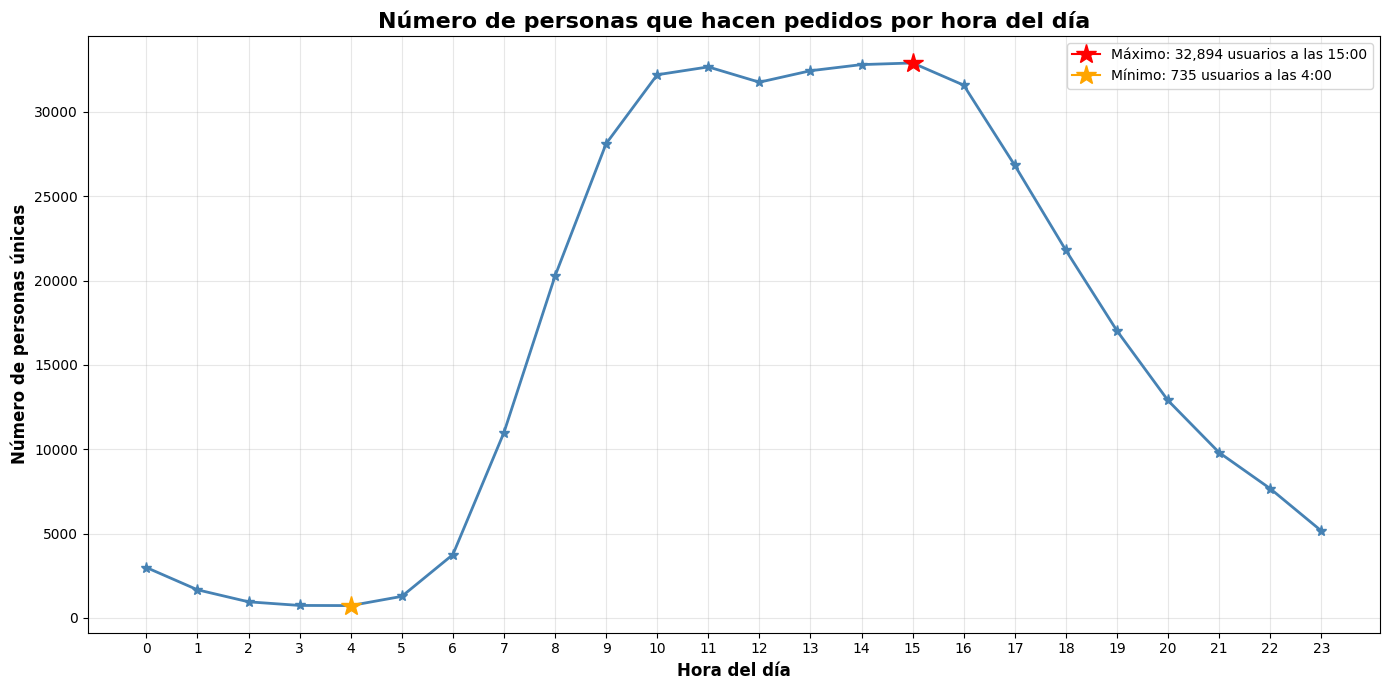

In [41]:
#gráfico que muestre el número de personas que hacen pedidos dependiendo la hora del día.

usuarios_por_hora = df_orders_sin_duplicados.groupby('order_hour_of_day')['user_id'].nunique()
plt.figure(figsize=(14, 7))

# Encontrar los valores máximo y mínimo
max_usuarios = usuarios_por_hora.max()
min_usuarios = usuarios_por_hora.min()
hora_max = usuarios_por_hora.idxmax()
hora_min = usuarios_por_hora.idxmin()

# Crear el gráfico base
plt.plot(usuarios_por_hora.index, usuarios_por_hora.values,
         marker='*', linewidth=2, markersize=8, color='steelblue')

# Resaltar el punto máximo
plt.plot(hora_max, max_usuarios, marker='*', markersize=15, color='red', 
         label=f'Máximo: {max_usuarios:,} usuarios a las {hora_max}:00')

# Resaltar el punto mínimo  
plt.plot(hora_min, min_usuarios, marker='*', markersize=15, color='orange',
         label=f'Mínimo: {min_usuarios:,} usuarios a las {hora_min}:00')

plt.title('Número de personas que hacen pedidos por hora del día', fontsize=16, fontweight='bold')
plt.xlabel('Hora del día', fontsize=12, fontweight='bold')
plt.ylabel('Número de personas únicas', fontsize=12, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
# Mostrar también los datos exactos
print("Datos exactos por hora:")
for hora, usuarios in usuarios_por_hora.items():
    print(f"Hora {hora:2d}: {usuarios:,} usuarios únicos")

Datos exactos por hora:
Hora  0: 2,991 usuarios únicos
Hora  1: 1,671 usuarios únicos
Hora  2: 958 usuarios únicos
Hora  3: 744 usuarios únicos
Hora  4: 735 usuarios únicos
Hora  5: 1,281 usuarios únicos
Hora  6: 3,757 usuarios únicos
Hora  7: 10,993 usuarios únicos
Hora  8: 20,268 usuarios únicos
Hora  9: 28,112 usuarios únicos
Hora 10: 32,195 usuarios únicos
Hora 11: 32,660 usuarios únicos
Hora 12: 31,754 usuarios únicos
Hora 13: 32,433 usuarios únicos
Hora 14: 32,797 usuarios únicos
Hora 15: 32,894 usuarios únicos
Hora 16: 31,579 usuarios únicos
Hora 17: 26,825 usuarios únicos
Hora 18: 21,795 usuarios únicos
Hora 19: 17,026 usuarios únicos
Hora 20: 12,891 usuarios únicos
Hora 21: 9,806 usuarios únicos
Hora 22: 7,670 usuarios únicos
Hora 23: 5,167 usuarios únicos



Escribe aquí tus conclusiones

Se optó por hacer la representación con un gráfico de líneas al no comparar distintas categorías, y  nos muestra un patrón porque las horas son secuenciales. Podemos apreciar un valle profundo entre las 00:00 y las 6:00. Entre las 10:00 y las 16:00 se mantiene una alza de mas de 30,000 usuarios por hora, y el pico máximo es a las 15:00 con 32,894 usuarios.


### [A3] ¿Qué día de la semana compran víveres las personas?

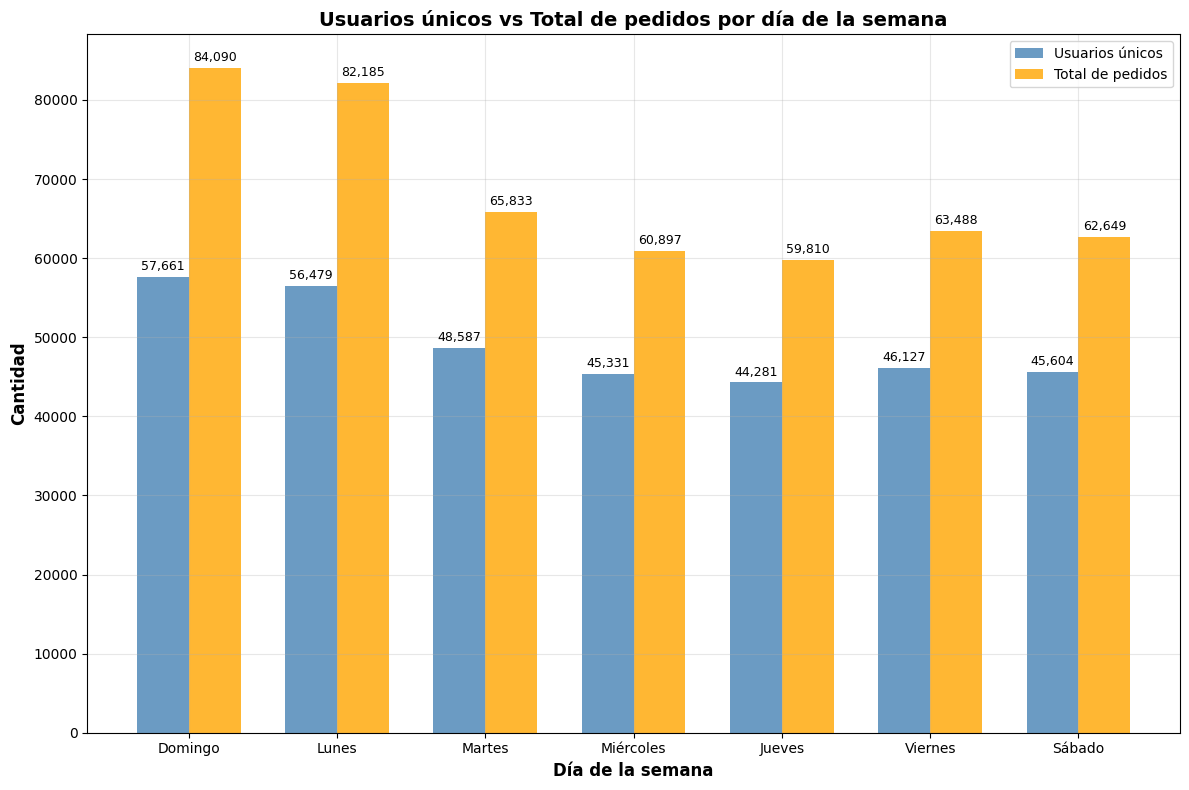

In [43]:

# Preparar los datos para ambas mostrar cuantos usuarios hacen pedidos por cada dia de la semana
usuarios_por_dia = df_orders_sin_duplicados.groupby('order_dow')['user_id'].nunique()
pedidos_por_dia = df_orders_sin_duplicados.groupby('order_dow').size()

# Crear nombres de días para mejor visualización, ya que los datos originales de la columna son del 0 al 6 
dias_semana = ['Domingo', 'Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado']

# Crear el gráfico con barras agrupadas
fig, ax = plt.subplots(figsize=(12, 8))

# Posiciones de las barras
x = range(len(dias_semana))
width = 0.35  # Ancho de las barras

# Crear las barras
bars1 = ax.bar([i - width/2 for i in x], usuarios_por_dia.values, width, 
               label='Usuarios únicos', color='steelblue', alpha=0.8)
bars2 = ax.bar([i + width/2 for i in x], pedidos_por_dia.values, width,
               label='Total de pedidos', color='orange', alpha=0.8)

# Personalizar el gráfico
ax.set_xlabel('Día de la semana', fontsize=12, fontweight='bold')
ax.set_ylabel('Cantidad', fontsize=12, fontweight='bold')
ax.set_title('Usuarios únicos vs Total de pedidos por día de la semana', 
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(dias_semana)
ax.legend()
ax.grid(True, alpha=0.3)

# Añadir valores en las barras
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 500,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 500,
            f'{int(height):,}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


Escribe aquí tus conclusiones
- El grafico nos muestra que el día que más pedidos se realizan es el domingo, donde 57,661 clientes unicos realizan un total de 84,090 pedidos.
- El segundo dia con más clientes haciendo pedidos es el lunes.
- El día menos activo es el jueves.


### [A4] ¿Cuánto tiempo esperan las personas hasta hacer otro pedido? Comenta sobre los valores mínimos y máximos.

In [ ]:
# Analizar la columna days_since_prior_order (excluyendo valores NaN)

tiempo_espera = df_orders_sin_duplicados['days_since_prior_order'].dropna()

print("Estadísticas del tiempo de espera entre pedidos:")
print(f"Valores mínimos: {tiempo_espera.min()}")
print(f"Valores máximos: {tiempo_espera.max()}")
print(f"Promedio: {tiempo_espera.mean():.2f} días")
print(f"Mediana: {tiempo_espera.median():.2f} días")
print(f"Total de pedidos con tiempo de espera: {len(tiempo_espera):,}")

Estadísticas del tiempo de espera entre pedidos:
Valores mínimos: 0.0
Valores máximos: 30.0
Promedio: 11.10 días
Mediana: 7.00 días
Total de pedidos con tiempo de espera: 450,135


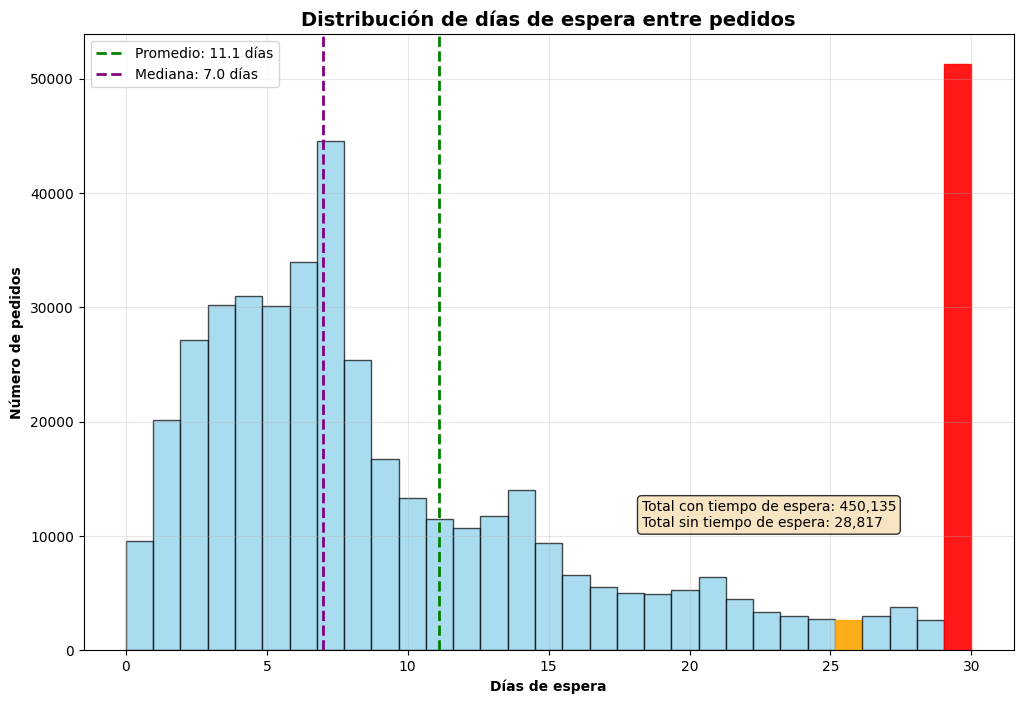

In [45]:
# Preparar los datos de la columna 'days_since_prior_order' eliminando los NaN con dropna, ya que esos valores no tienen tiempo de espera.
tiempo_espera = df_orders_sin_duplicados['days_since_prior_order'].dropna()

# Calcular estadísticas
promedio = tiempo_espera.mean()
mediana = tiempo_espera.median()
total_con_tiempo = len(tiempo_espera)
total_sin_tiempo = df_orders_sin_duplicados['days_since_prior_order'].isna().sum()

# Crear el histograma con plt.hist()ya que nos da mayor flexibilidad a la hora de personalizar el gráfico
plt.figure(figsize=(12, 8))
counts, bins, patches = plt.hist(tiempo_espera, bins=31, range=(0, 30), color='skyblue', alpha=0.7, edgecolor='black')

# Encontrar el bin con mayor y menor frecuencia
max_count_idx = counts.argmax()
min_count_idx = counts.argmin()

# Cambiar colores para máximo y mínimo
patches[max_count_idx].set_color('red')
patches[max_count_idx].set_alpha(0.9)
patches[min_count_idx].set_color('orange') 
patches[min_count_idx].set_alpha(0.9)

# Agregar líneas para promedio y mediana
plt.axvline(promedio, color='green', linestyle='--', linewidth=2, label=f'Promedio: {promedio:.1f} días')
plt.axvline(mediana, color='purple', linestyle='--', linewidth=2, label=f'Mediana: {mediana:.1f} días')

#personalizar titulos, etiquetas, leyenda, asi como agregar texto informativo 
plt.title('Distribución de días de espera entre pedidos', fontweight='bold', fontsize=14)
plt.xlabel('Días de espera', fontweight='bold')
plt.ylabel('Número de pedidos', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.text(0.6, 0.2, f'Total con tiempo de espera: {total_con_tiempo:,}\nTotal sin tiempo de espera: {total_sin_tiempo:,}', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='wheat', alpha=0.8))

plt.show()

In [ ]:
#obtener numeros exactos de pedidos en cada día de espera  
tiempo_espera = df_orders_sin_duplicados['days_since_prior_order'].dropna()
conteo_por_dia = tiempo_espera.value_counts().sort_index()
print("Conteo real por día:")
for dia, cantidad in conteo_por_dia.items():
    print(f"Día {dia}: {cantidad:,} pedidos")
# Encontrar el día con menor y mayor número de pedidos
dia_min = conteo_por_dia.idxmin()
pedidos_min = conteo_por_dia.min()
dia_max = conteo_por_dia.idxmax()
pedidos_max = conteo_por_dia.max()

print(f"Mínimo real: {pedidos_min:,} pedidos en el día {dia_min}")
print(f"Máximo real: {pedidos_max:,} pedidos en el día {dia_max}")

Conteo real por día:
Día 0.0: 9,589 pedidos
Día 1.0: 20,179 pedidos
Día 2.0: 27,138 pedidos
Día 3.0: 30,224 pedidos
Día 4.0: 31,006 pedidos
Día 5.0: 30,096 pedidos
Día 6.0: 33,930 pedidos
Día 7.0: 44,577 pedidos
Día 8.0: 25,361 pedidos
Día 9.0: 16,753 pedidos
Día 10.0: 13,309 pedidos
Día 11.0: 11,467 pedidos
Día 12.0: 10,658 pedidos
Día 13.0: 11,737 pedidos
Día 14.0: 13,992 pedidos
Día 15.0: 9,416 pedidos
Día 16.0: 6,587 pedidos
Día 17.0: 5,498 pedidos
Día 18.0: 4,971 pedidos
Día 19.0: 4,939 pedidos
Día 20.0: 5,302 pedidos
Día 21.0: 6,448 pedidos
Día 22.0: 4,514 pedidos
Día 23.0: 3,337 pedidos
Día 24.0: 3,015 pedidos
Día 25.0: 2,711 pedidos
Día 26.0: 2,640 pedidos
Día 27.0: 2,986 pedidos
Día 28.0: 3,745 pedidos
Día 29.0: 2,673 pedidos
Día 30.0: 51,337 pedidos
Mínimo real: 2,640 pedidos en el día 26.0
Máximo real: 51,337 pedidos en el día 30.0


Escribe aquí tus conclusiones
 - De un total de 450,135 pedidos, el tiempo máximo de espera es de 30 días, mientras que el promedio es de 11 dias.
- El histograma se muestra sesgado a la izquierda y con un pico que justo nos indica la media (44,577), y de ahi va disminuyendo la cantidad de pedidos que se piden con más de 7 dias de espera.
- Hay 28,817 pedidos que no tienen tiempo de espera porque son pedidos por primera vez y se identifican como NaN.
- El día 26 es cuando menos pedidos se realizan (2,640)
- El día 30 tiene la mayor cantidad de pedidos (51,337), posiblemente porque representa el límite máximo del sistema.

# [B] Intermedio (deben completarse todos para aprobar)
1. ¿Existe alguna diferencia entre las distribuciones `'order_hour_of_day'` de los miércoles y los sábados? Traza gráficos de barra de `'order_hour_of_day'` para ambos días en la misma figura y describe las diferencias que observes.
2. Grafica la distribución para el número de órdenes que hacen los clientes (es decir, cuántos clientes hicieron solo 1 pedido, cuántos hicieron 2, cuántos 3, y así sucesivamente...).
3. ¿Cuáles son los 20 principales productos que se piden con más frecuencia (muestra su identificación y nombre)?

### [B1] Diferencia entre miércoles y sábados para  `'order_hour_of_day'`. Traza gráficos de barra para los dos días y describe las diferencias que veas.

In [47]:
#Preparar datos de ambos días.

pedidos_miercoles = df_orders_sin_duplicados[df_orders_sin_duplicados['order_dow']== 3]
pedidos_sabados = df_orders_sin_duplicados[df_orders_sin_duplicados['order_dow'] == 6]

print(f"Pedidos de miércoles: {len(pedidos_miercoles):,}")
print(f"Pedidos de sábados: {len(pedidos_sabados):,}")

distribucion_miercoles = pedidos_miercoles['order_hour_of_day'].value_counts().sort_index()
distribucion_sabados = pedidos_sabados['order_hour_of_day'].value_counts().sort_index()

display(distribucion_miercoles , distribucion_sabados)



Pedidos de miércoles: 60,897
Pedidos de sábados: 62,649


0      373
1      215
2      106
3      101
4      108
5      170
6      643
7     1732
8     3125
9     4490
10    5026
11    5004
12    4688
13    4674
14    4774
15    5163
16    4976
17    4175
18    3463
19    2652
20    1917
21    1450
22    1154
23     718
Name: order_hour_of_day, dtype: int64

0      464
1      254
2      177
3      125
4      118
5      161
6      451
7     1619
8     3246
9     4311
10    4919
11    5116
12    5132
13    5323
14    5375
15    5188
16    5029
17    4295
18    3338
19    2610
20    1847
21    1473
22    1185
23     893
Name: order_hour_of_day, dtype: int64

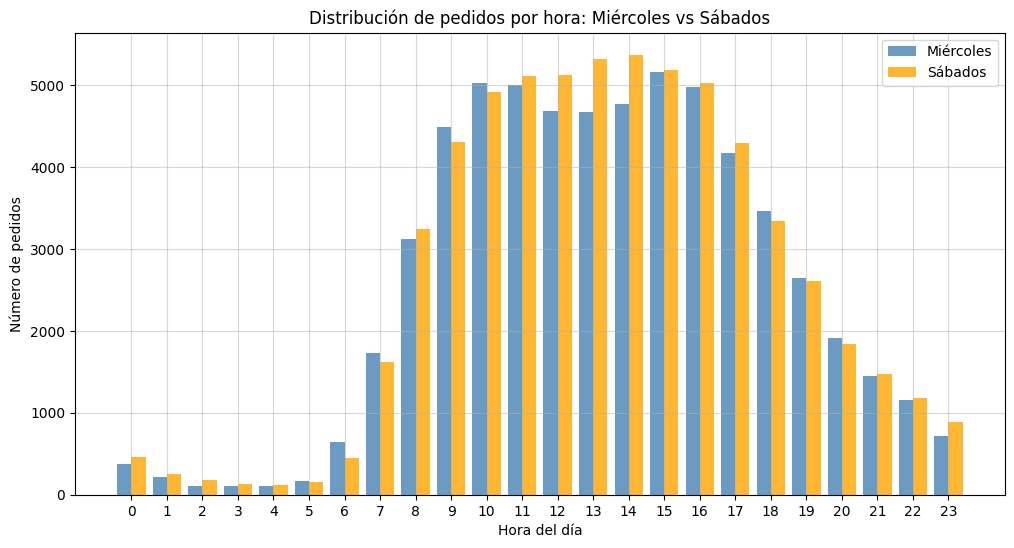

In [48]:
#Creamos el gráfico

plt.figure(figsize=(12, 6))
#ancho de barras y posiciones
width = 0.4 #ancho de cada barra
x = range(24) #posiciones (0 a 23)
#crear barras lado a lado
plt.bar([i - width/2 for i in x], distribucion_miercoles.values, width, label='Miércoles', color='steelblue', alpha=0.8)
plt.bar([i + width/2 for i in x], distribucion_sabados.values, width, label='Sábados', color='orange', alpha=0.8)
plt.xlabel('Hora del día')
plt.ylabel('Número de pedidos')
plt.title('Distribución de pedidos por hora: Miércoles vs Sábados')
plt.legend()
plt.grid(True, alpha=0.5)
plt.xticks(range(0,24))
plt.show()


In [49]:

# Análisis estadístico de las diferencias
diferencias = distribucion_sabados - distribucion_miercoles

print("=== ANÁLISIS COMPARATIVO MIÉRCOLES VS SÁBADOS ===")
print(f"Total pedidos miércoles: {distribucion_miercoles.sum():,}")
print(f"Total pedidos sábados: {distribucion_sabados.sum():,}")
print(f"Diferencia total: {distribucion_sabados.sum() - distribucion_miercoles.sum():,}")

print("\n=== HORAS PICO ===")
print(f"Hora pico miércoles: {distribucion_miercoles.idxmax()}:00 ({distribucion_miercoles.max():,} pedidos)")
print(f"Hora pico sábados: {distribucion_sabados.idxmax()}:00 ({distribucion_sabados.max():,} pedidos)")

print("\n=== MAYORES DIFERENCIAS ===")
print("Horas donde sábados superan significativamente a miércoles:")
diferencias_positivas = diferencias[diferencias > 200].sort_values(ascending=False)
for hora, diff in diferencias_positivas.head(5).items():
    print(f"  {hora}:00 - Sábados tienen {diff:,} pedidos más")


=== ANÁLISIS COMPARATIVO MIÉRCOLES VS SÁBADOS ===
Total pedidos miércoles: 60,897
Total pedidos sábados: 62,649
Diferencia total: 1,752

=== HORAS PICO ===
Hora pico miércoles: 15:00 (5,163 pedidos)
Hora pico sábados: 14:00 (5,375 pedidos)

=== MAYORES DIFERENCIAS ===
Horas donde sábados superan significativamente a miércoles:
  13:00 - Sábados tienen 649 pedidos más
  14:00 - Sábados tienen 601 pedidos más
  12:00 - Sábados tienen 444 pedidos más


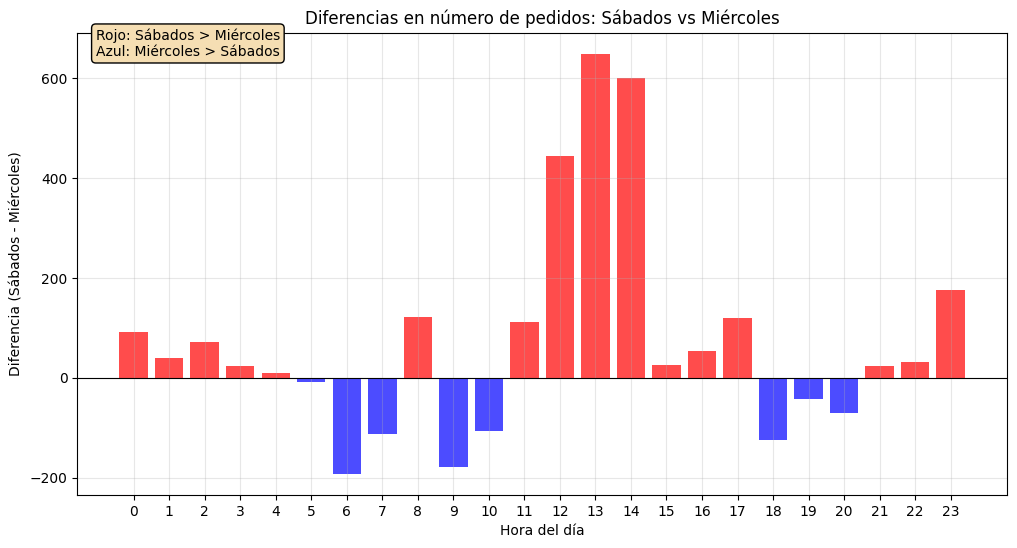

In [ ]:

# Visualización de las diferencias
plt.figure(figsize=(12, 6))
plt.bar(diferencias.index, diferencias.values, 
        color=['red' if x > 0 else 'blue' for x in diferencias.values],
        alpha=0.7)
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
plt.xlabel('Hora del día')
plt.ylabel('Diferencia (Sábados - Miércoles)')
plt.title('Diferencias en número de pedidos: Sábados vs Miércoles')
plt.grid(True, alpha=0.3)
plt.xticks(range(0, 24))

plt.text(0.02, 0.95, 'Rojo: Sábados > Miércoles\nAzul: Miércoles > Sábados', 
         transform=plt.gca().transAxes, bbox=dict(boxstyle="round", facecolor='wheat'))
plt.show()

Escribe aquí tus conclusiones
- Los días miercoles y sábados tenemos un total de 60,897 y 62,649 respectivamente.Vamos a profundizar más a detalle el comportamiendo te la distribucion para cada hora de estos 2 dias.
- La distribución de pedidos los días miercoles tiene una disminucion entre 11 y 14 hrs. en cambio en dias sabados las mismas horas tenemos incremento de pedidos, con el valor mas alto alas 2 pm. Lo anterior podría deberse a que los hábitos de compra cambian entre días laborales y fines de semana.
- La diferencia entre el número de pedidos de miércoles y sábado es de 1,752 pedidos más en sábado.
- La hora pico de pedidos para los miércoles es a las 3 pm con un total de 5,163 pedidos.
- La hora pico de pedidos para los sábados es a las 2 pm con un total de 5,375 pedidos.
- Los días sábados de 12 a 14 hrs, existe un incremento siginificativo en el número de pedidos respecto al miércoles, ya que es la hora del lunch en días laborales.

### [B2] ¿Cuál es la distribución para el número de pedidos por cliente?

Nota: Se agregó otra celda con grafica de barras para comparación, pero se tuvo que ajustar para escala logarítmica ya que las barras de la derecha no se visualizaban. Si es una buena diferencia. Pero la gráfica de líneas que coloqué originalmente, al tener valores en cada marcador, considero que también es buena opción. 

In [51]:
#prepararlasdatos
pedidos_por_cliente = df_orders_sin_duplicados.groupby('user_id').size()
distribucion_pedidos = pedidos_por_cliente.value_counts().sort_index()

display(pedidos_por_cliente, distribucion_pedidos)

user_id
2         2
4         2
5         1
6         2
7         2
         ..
206203    1
206206    7
206207    5
206208    9
206209    2
Length: 157437, dtype: int64

1     55357
2     36508
3     21547
4     13498
5      8777
6      6012
7      4240
8      3019
9      2152
10     1645
11     1308
12      947
13      703
14      512
15      437
16      263
17      184
18      121
19       85
20       52
21       22
22       23
23       19
24        3
25        1
26        1
28        1
dtype: int64

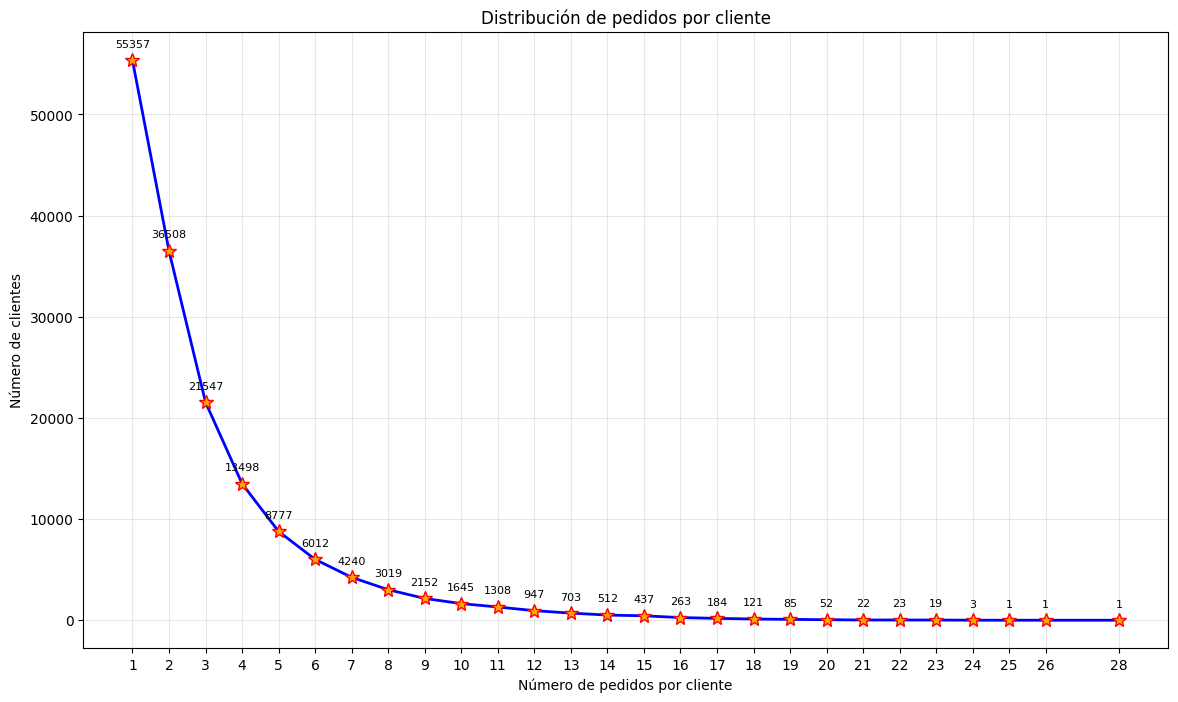

Resumen de la distribución:
Total de clientes: 157,437
Top 5 de distribución de pedidos
Clientes con 1 pedido: 55,357 (35.2%)
Clientes con 2 pedidos: 36,508 (23.2%)
Clientes con 3 pedidos: 21,547 (13.7%)
Clientes con 4 pedidos: 13,498 (8.6%)
Clientes con 5 pedidos: 8,777 (5.6%)


In [52]:

#gráfico

plt.figure(figsize=(14, 8))
plt.plot(distribucion_pedidos.index, distribucion_pedidos.values, 
         marker='*', linewidth=2, markersize=10, color='blue', markerfacecolor='orange', markeredgecolor='red')
plt.xlabel('Número de pedidos por cliente')
plt.ylabel('Número de clientes')
plt.title('Distribución de pedidos por cliente')
plt.grid(True, alpha=0.3)

# Mostrar todos los valores del eje x
plt.xticks(distribucion_pedidos.index)

# Agregar valores a cada punto
for x, y in zip(distribucion_pedidos.index, distribucion_pedidos.values):
    plt.text(x, y + max(distribucion_pedidos.values) * 0.02, str(y), ha='center', va='bottom', fontsize=8)

plt.show()

print("Resumen de la distribución:")
print(f"Total de clientes: {distribucion_pedidos.sum():,}")
print(f"Top 5 de distribución de pedidos")
print(f"Clientes con 1 pedido: {distribucion_pedidos[1]:,} ({distribucion_pedidos[1]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 2 pedidos: {distribucion_pedidos[2]:,} ({distribucion_pedidos[2]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 3 pedidos: {distribucion_pedidos[3]:,} ({distribucion_pedidos[3]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 4 pedidos: {distribucion_pedidos[4]:,} ({distribucion_pedidos[4]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 5 pedidos: {distribucion_pedidos[5]:,} ({distribucion_pedidos[5]/distribucion_pedidos.sum()*100:.1f}%)")


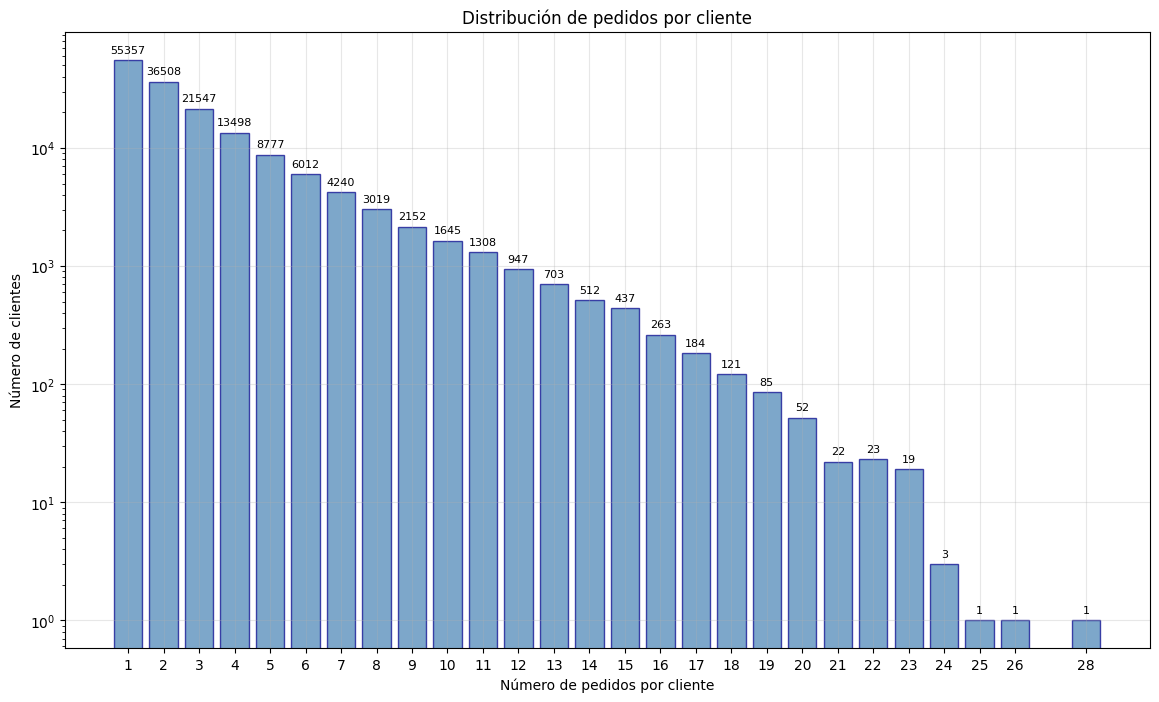

Resumen de la distribución:
Total de clientes: 157,437
Top 5 de distribución de pedidos
Clientes con 1 pedido: 55,357 (35.2%)
Clientes con 2 pedidos: 36,508 (23.2%)
Clientes con 3 pedidos: 21,547 (13.7%)
Clientes con 4 pedidos: 13,498 (8.6%)
Clientes con 5 pedidos: 8,777 (5.6%)


In [53]:
#muestra de grafico en barras
#gráfico

plt.figure(figsize=(14, 8))
plt.bar(distribucion_pedidos.index, distribucion_pedidos.values, 
          color='steelblue', alpha=0.7, edgecolor='darkblue', linewidth=1)
plt.xlabel('Número de pedidos por cliente')
plt.ylabel('Número de clientes')
plt.title('Distribución de pedidos por cliente')
plt.grid(True, alpha=0.3)
plt.yscale('log')
# Mostrar todos los valores del eje x
plt.xticks(distribucion_pedidos.index)

# Agregar valores a cada punto

for x, y in zip(distribucion_pedidos.index, distribucion_pedidos.values):
    plt.text(x, y * 1.1, str(y), ha='center', va='bottom', fontsize=8)


plt.show()

print("Resumen de la distribución:")
print(f"Total de clientes: {distribucion_pedidos.sum():,}")
print(f"Top 5 de distribución de pedidos")
print(f"Clientes con 1 pedido: {distribucion_pedidos[1]:,} ({distribucion_pedidos[1]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 2 pedidos: {distribucion_pedidos[2]:,} ({distribucion_pedidos[2]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 3 pedidos: {distribucion_pedidos[3]:,} ({distribucion_pedidos[3]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 4 pedidos: {distribucion_pedidos[4]:,} ({distribucion_pedidos[4]/distribucion_pedidos.sum()*100:.1f}%)")
print(f"Clientes con 5 pedidos: {distribucion_pedidos[5]:,} ({distribucion_pedidos[5]/distribucion_pedidos.sum()*100:.1f}%)")


Escribe aquí tus conclusiones
- Se tienen registros de un total de 157,437 clientes únicos que compraron en instacart
- El mayor número de pedidos de un solo cliente fue de 28 pedidos,en segundo lugar el mayor número de pedidos es de 26 para otro cliente y en tercer lugar 25 pedidos de otro solo cliente.
- El mayor porcentaje de clientes que compran en instacart solo lo han hecho una sola vez, y es del 35.2% equivalente a 55,357 personas. 
- Hay 36,508 personas que compraron en instacart 2 veces, es decir un 23.2% del total.
- Hay 21,547 personas que compraron en instacart 3 veces, es decir un 13.7%.
- La frecuencia de pedidos va disminuyendo cada vez más.
- Mas del 50% de clientes de instacart, han hecho pedidos solo 1 o 2 veces.

### [B3] ¿Cuáles son los 20 productos más populares (muestra su ID y nombre)?

In [54]:
#preparamos los datos.

top_20_count=(df_order_products['product_id'].value_counts().head(20))

top_20_df = pd.DataFrame({'product_id': top_20_count.index,'cantidad_pedidos': top_20_count.values})

print("Contador de Id de productos mas populares:")
display(top_20_df)

#codigo adicional para visuaizar ID y Nombre 
top_20_productos_final = top_20_con_nombres[['product_id', 'product_name', 'cantidad_pedidos']]
print("=== TOP 20 PRODUCTOS MÁS PEDIDOS ===")
print("ID del Producto | Nombre del Producto | Veces Pedido")
print("-" * 60)
for _, row in top_20_productos_final.iterrows():
    print(f"{row['product_id']:>6} | {row['product_name']:<35} | {row['cantidad_pedidos']:>8}")

Contador de Id de productos mas populares:


,product_id,cantidad_pedidos
0,24852,66050
1,13176,53297
2,21137,37039
3,21903,33971
4,47209,29773
5,47766,24689
6,47626,21495
7,16797,20018
8,26209,19690
9,27845,19600


NameError: name 'top_20_con_nombres' is not defined

In [55]:

# Hacer merge con df_products para obtener nombres
top_20_con_nombres = top_20_df.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')
#ajuste en codigo para cambiar orden de visualizacion en columnas
top_20_con_nombres = top_20_con_nombres[['product_id', 'product_name', 'cantidad_pedidos']]
print("Los 20 productos más populares con nombres:")
display(top_20_con_nombres)

Los 20 productos más populares con nombres:


,product_id,product_name,cantidad_pedidos
0,24852,Banana,66050
1,13176,Bag of Organic Bananas,53297
2,21137,Organic Strawberries,37039
3,21903,Organic Baby Spinach,33971
4,47209,Organic Hass Avocado,29773
5,47766,Organic Avocado,24689
6,47626,Large Lemon,21495
7,16797,Strawberries,20018
8,26209,Limes,19690
9,27845,Organic Whole Milk,19600


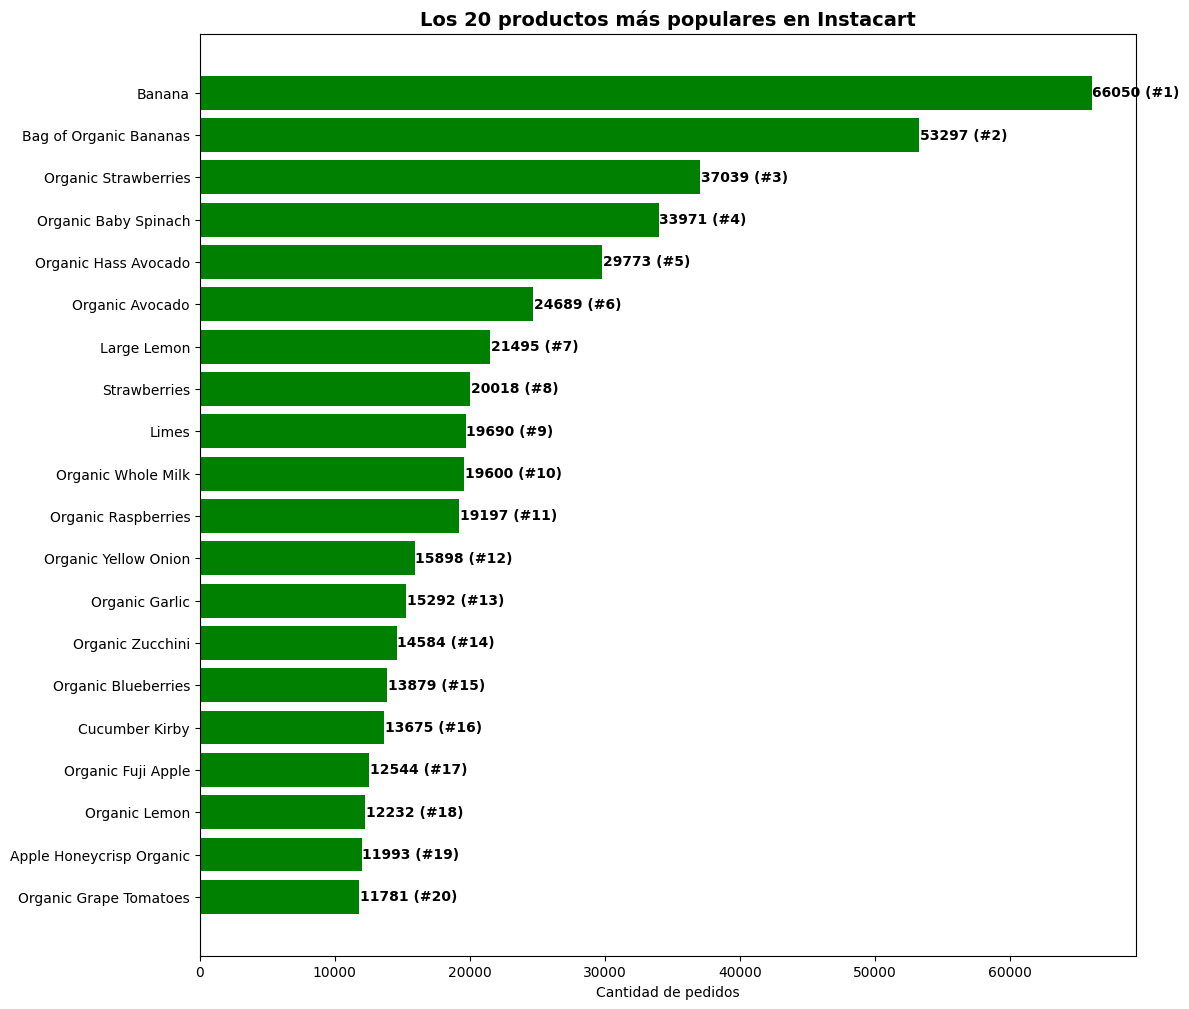

In [56]:
# Crear gráfico de barras horizontal para visualizacion más llamativa
plt.figure(figsize=(12, 10))
bars = plt.barh(range(len(top_20_con_nombres)), top_20_con_nombres['cantidad_pedidos'], color='green')
plt.yticks(range(len(top_20_con_nombres)), top_20_con_nombres['product_name'])

for i, (cantidad, bar) in enumerate(zip(top_20_con_nombres['cantidad_pedidos'], bars)):

    plt.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2, f'{cantidad} (#{i+1})', va='center', ha='left', fontweight='bold')

plt.title('Los 20 productos más populares en Instacart', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()  
plt.tight_layout()
plt.xlabel('Cantidad de pedidos')
plt.show()


Escribe aquí tus conclusiones
- Se usaron los datos de 2 data frames con el metodo .merge() order_products y products.
- El gráfico nos muestra el ranking de 20 productos mas pedidos en Instacart.
- El producto mas popular es la banana y en segundo lugar la bolsa de bananas orgánicas.

# [C] Difícil (deben completarse todos para aprobar)

1. ¿Cuántos artículos suelen comprar las personas en un pedido? ¿Cómo es la distribución?
2. ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?
3. Para cada producto, ¿cuál es la tasa de repetición del pedido (número de repeticiones de pedido/total de pedidos?
4. Para cada cliente, ¿qué proporción de los productos que pidió ya los había pedido? Calcula la tasa de repetición de pedido para cada usuario en lugar de para cada producto.
5. ¿Cuáles son los 20 principales artículos que la gente pone primero en sus carritos (muestra las IDs de los productos, sus nombres, y el número de veces en que fueron el primer artículo en añadirse al carrito)?
   

### [C1] ¿Cuántos artículos compran normalmente las personas en un pedido? ¿Cómo es la distribución?

In [57]:
#preparar datos
productos_por_pedido = df_order_products.groupby('order_id')['product_id'].size()
conteo_productos = productos_por_pedido.value_counts().sort_index()
print(productos_por_pedido.describe())
valor_mas_alto = conteo_productos.max()
numero_productos_en_pico = conteo_productos.idxmax()

print(f"El valor más alto es: {valor_mas_alto:,} pedidos")
print(f"Corresponde a pedidos con: {numero_productos_en_pico} productos")


count    450046.000000
mean         10.098983
std           7.540206
min           1.000000
25%           5.000000
50%           8.000000
75%          14.000000
max         127.000000
Name: product_id, dtype: float64
El valor más alto es: 31,923 pedidos
Corresponde a pedidos con: 5 productos


In [58]:
#identificacion de pedidos mas grandes
pedidos_grandes = productos_por_pedido[productos_por_pedido > 30]
print(f"Pedidos con más de 30 productos: {len(pedidos_grandes)}")
print(f"Porcentaje del total: {len(pedidos_grandes)/len(productos_por_pedido)*100:.2f}%")

rangos = [1, 2, 3, 4, 5, 10, 20, 50, 127]
productos_por_pedido_cut = pd.cut(productos_por_pedido, bins=rangos, include_lowest=True)
tabla_rangos = productos_por_pedido_cut.value_counts().sort_index()
tabla_rangos_df = pd.DataFrame({
    'Rango de Productos': tabla_rangos.index,
    'Número de Pedidos': tabla_rangos.values
})

print("=== DISTRIBUCIÓN DE PRODUCTOS POR PEDIDO ===")
display(tabla_rangos_df)

Pedidos con más de 30 productos: 9249
Porcentaje del total: 2.06%
=== DISTRIBUCIÓN DE PRODUCTOS POR PEDIDO ===


,Rango de Productos,Número de Pedidos
0,"(0.999, 2.0]",48139
1,"(2.0, 3.0]",29046
2,"(3.0, 4.0]",31054
3,"(4.0, 5.0]",31923
4,"(5.0, 10.0]",140049
5,"(10.0, 20.0]",127186
6,"(20.0, 50.0]",42220
7,"(50.0, 127.0]",429


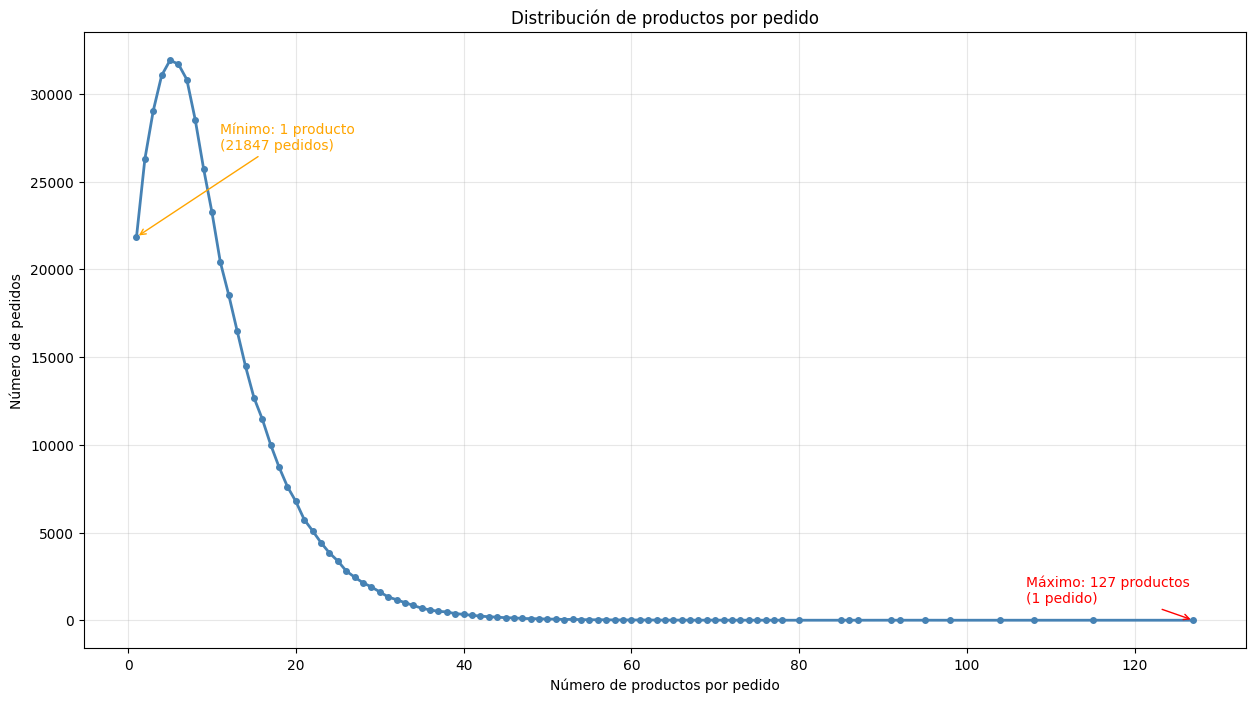

In [59]:

#grafica para visualizar distribucion
conteo_productos = productos_por_pedido.value_counts().sort_index()

plt.figure(figsize=(15, 8))
plt.plot(conteo_productos.index, conteo_productos.values, 
         marker='o', linewidth=2, markersize=4, color='steelblue')
plt.title('Distribución de productos por pedido')
plt.xlabel('Número de productos por pedido')
plt.ylabel('Número de pedidos')
plt.grid(True, alpha=0.3)

max_productos = conteo_productos.index.max()
min_productos = conteo_productos.index.min()
max_pedidos = conteo_productos.max()
min_pedidos = conteo_productos.min()

plt.annotate(f'Máximo: {max_productos} productos\n({conteo_productos[max_productos]} pedido)', 
             xy=(max_productos, conteo_productos[max_productos]), 
             xytext=(max_productos-20, conteo_productos[max_productos]+1000),
             arrowprops=dict(arrowstyle='->', color='red'),
             fontsize=10, color='red')

plt.annotate(f'Mínimo: {min_productos} producto\n({conteo_productos[min_productos]} pedidos)', 
             xy=(min_productos, conteo_productos[min_productos]), 
             xytext=(min_productos+10, conteo_productos[min_productos]+5000),
             arrowprops=dict(arrowstyle='->', color='orange'),
             fontsize=10, color='orange')

plt.show()


Escribe aquí tus conclusiones

- El valor mínimo de productos es de 1 por pedido, y en esta condicion tenemos 21847 pedidos.
- El valor máximo de productos por pedido es de 127, sin embargo solo hubo un pedido en esta condición.
- El valor que más frecuentemente se presenta de productos por pedido es 5, teniendo un total de 31,923 pedidos  en esta condición.
  



### [C2] ¿Cuáles son los 20 principales artículos que vuelven a pedirse con mayor frecuencia (muestra sus nombres e IDs de los productos)?

In [ ]:
#preparar los datos

productos_reordenados = df_order_products[df_order_products['reordered'] == 1]
top_20_reordered = productos_reordenados['product_id'].value_counts().head(20)

top_20_reordered_df = pd.DataFrame({'product_id': top_20_reordered.index,
                                   'frecuencia_recompra': top_20_reordered.values})
print("Los 20 productos que se reordenan mas polulares en Instacart:")
display(top_20_reordered_df)

Los 20 productos que se reordenan mas polulares en Instacart:


,product_id,frecuencia_recompra
0,24852,55763
1,13176,44450
2,21137,28639
3,21903,26233
4,47209,23629
5,47766,18743
6,27845,16251
7,47626,15044
8,27966,14748
9,16797,13945


In [ ]:
# Verificar el resultado específico de producto con ID 24852 para validar que se realizó el conteo correctamente
producto_24852 = productos_reordenados[productos_reordenados['product_id'] == 24852]
print(f"Producto 24852 - Total de recompras: {len(producto_24852):,}")

# Verificar que sea efectivamente el más alto
print(f"¿Es el más alto? {top_20_reordered.iloc[0] == 55763}")
print(f"Producto ID del más alto: {top_20_reordered.index[0]}")

Producto 24852 - Total de recompras: 55,763
¿Es el más alto? True
Producto ID del más alto: 24852


In [ ]:

# Hacer merge con la tabla de productos para ver el nombre
top_20_reordered_con_nombres = top_20_reordered_df.merge(
    df_products[['product_id', 'product_name']], on='product_id', how='left')

#ajuste para orden de columnas
top_20_reordered_con_nombres = top_20_reordered_con_nombres[['product_id', 'product_name', 'frecuencia_recompra']]

print("Top 20 productos que se vuelven a pedir:")
display(top_20_reordered_con_nombres)

# Ver específicamente el producto más reordenado
producto_top = df_products[df_products['product_id'] == 24852]['product_name'].iloc[0]
print(f"El producto más reordenado es: {producto_top}")

Top 20 productos que se vuelven a pedir:


,product_id,product_name,frecuencia_recompra
0,24852,Banana,55763
1,13176,Bag of Organic Bananas,44450
2,21137,Organic Strawberries,28639
3,21903,Organic Baby Spinach,26233
4,47209,Organic Hass Avocado,23629
5,47766,Organic Avocado,18743
6,27845,Organic Whole Milk,16251
7,47626,Large Lemon,15044
8,27966,Organic Raspberries,14748
9,16797,Strawberries,13945


El producto más reordenado es: Banana


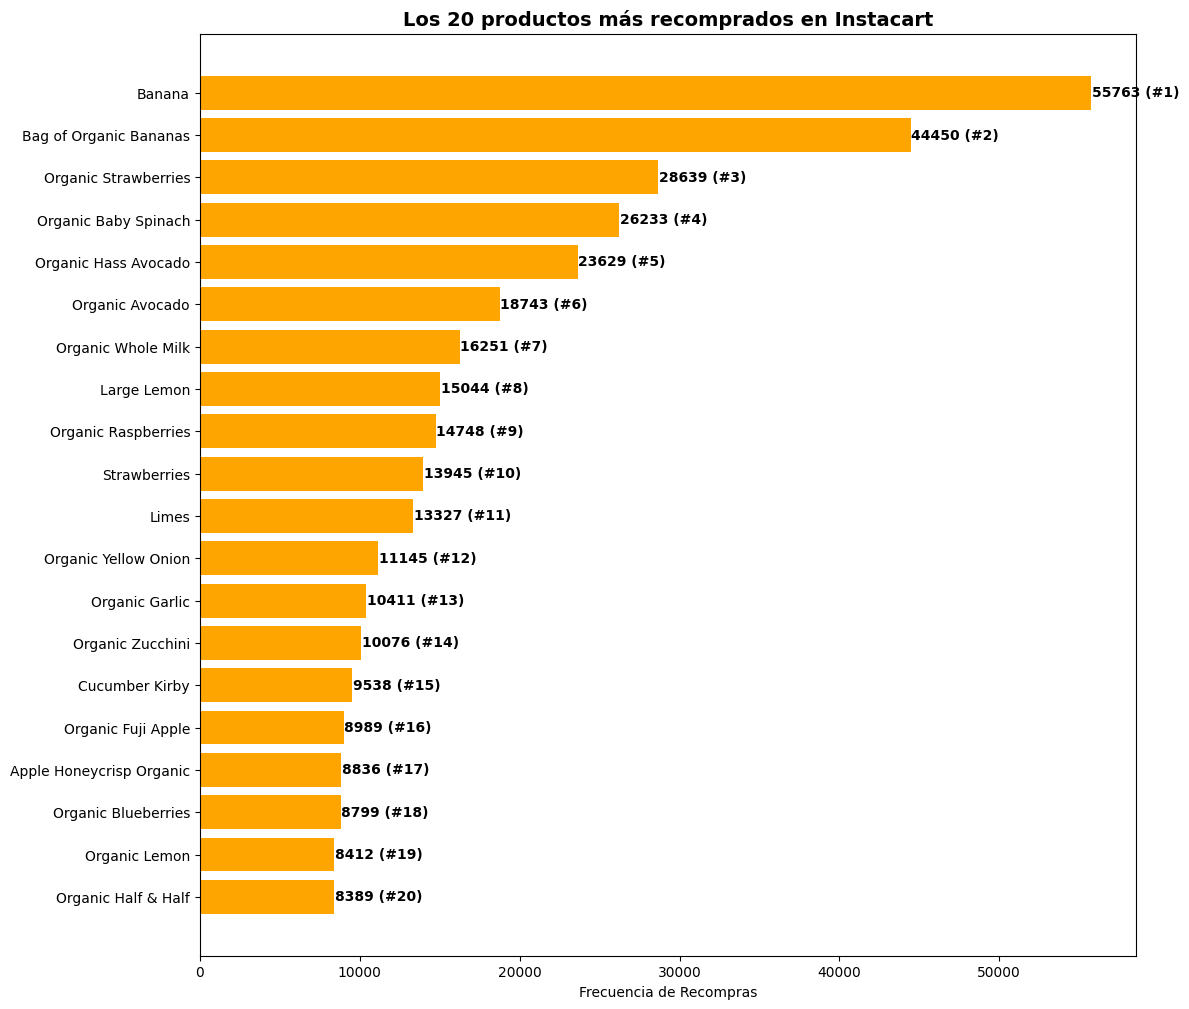

In [63]:

#crear gráfico para visualización de la tabla anterior
plt.figure(figsize=(12, 10))
bars = plt.barh(range(len(top_20_reordered_con_nombres)), top_20_reordered_con_nombres['frecuencia_recompra'],
                color='orange')

# Configurar etiquetas del eje Y 
plt.yticks(range(len(top_20_reordered_con_nombres)), top_20_reordered_con_nombres['product_name'])

# Agregar anotaciones en cada barra
for i, (cantidad, bar) in enumerate(zip(top_20_reordered_con_nombres['frecuencia_recompra'], bars)):
    # Posición del texto: al final de la barra
    plt.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             f'{cantidad} (#{i+1})',
             va='center', ha='left', fontweight='bold')

plt.title('Los 20 productos más recomprados en Instacart', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()  
plt.tight_layout()

plt.xlabel('Frecuencia de Recompras')
plt.show()


Escribe aquí tus conclusiones
- Los productos más recomprados son los mismos del Top 20 de productos más polulares.
- Estos productos son básicos o esenciales, como frutas, leche y vegetales, por lo tanto son productos de consumo frecuente.
- Nos indica que son productos de calidad al ser recomprados porque generaron satisfacción desde la primera compra.

### [C3] Para cada producto, ¿cuál es la proporción de las veces que se pide y que se vuelve a pedir?

In [ ]:

#preparar datos
total_por_producto = df_order_products.groupby('product_id').size()
recompras_por_producto = df_order_products[df_order_products['reordered'] == 1].groupby('product_id').size()

proporcion_reorden = pd.DataFrame({
    'total_pedidos': total_por_producto,
    'recompras': recompras_por_producto
}).fillna(0)  # Llenar NaN con 0 para productos nunca recomprados

# Calcular proporción
proporcion_reorden['proporcion'] = proporcion_reorden['recompras'] / proporcion_reorden['total_pedidos']
#resetear indices
proporcion_reorden_reset = proporcion_reorden.reset_index()
# Agregar nombres de productos
proporcion_reorden_con_nombres = proporcion_reorden_reset.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')
# Ordenar las columnas
proporcion_reorden_con_nombres = proporcion_reorden_con_nombres[['product_id', 'product_name', 'proporcion', 'total_pedidos', 'recompras']]
# Mostrar la tabla completa de proporciones (primeras 20 filas como ejemplo)

print("Tabla de proporciones de recompra por producto:")
display(proporcion_reorden_con_nombres.head(20))

print(f"\nTotal de productos analizados: {len(proporcion_reorden_con_nombres)}")
# Estadísticas descriptivas de las proporciones
print("Estadísticas de las proporciones de recompra:")
display(proporcion_reorden_con_nombres['proporcion'].describe())

# Ver los productos con más pedidos totales
productos_mas_pedidos = proporcion_reorden_con_nombres.sort_values('total_pedidos', ascending=False).head(20)
print("Top 20 productos con más pedidos totales:")
display(productos_mas_pedidos)

# Ver los productos con más recompras absolutas
productos_mas_recompras = proporcion_reorden_con_nombres.sort_values('recompras', ascending=False).head(20)
print("Top 20 productos con más recompras absolutas:")
display(productos_mas_recompras)

Tabla de proporciones de recompra por producto:


,product_id,product_name,proporcion,total_pedidos,recompras
0,1,Chocolate Sandwich Cookies,0.564286,280,158.0
1,2,All-Seasons Salt,0.000000,11,0.0
2,3,Robust Golden Unsweetened Oolong Tea,0.738095,42,31.0
3,4,Smart Ones Classic Favorites Mini Rigatoni Wit...,0.510204,49,25.0
4,7,Pure Coconut Water With Orange,0.500000,2,1.0
5,8,Cut Russet Potatoes Steam N' Mash,0.315789,19,6.0
6,9,Light Strawberry Blueberry Yogurt,0.761905,21,16.0
7,10,Sparkling Orange Juice & Prickly Pear Beverage,0.448071,337,151.0
8,11,Peach Mango Juice,0.625000,16,10.0
9,12,Chocolate Fudge Layer Cake,0.390244,41,16.0



Total de productos analizados: 45573
Estadísticas de las proporciones de recompra:


count    45573.000000
mean         0.386707
std          0.272132
min          0.000000
25%          0.166667
50%          0.408163
75%          0.575758
max          1.000000
Name: proporcion, dtype: float64

Top 20 productos con más pedidos totales:


,product_id,product_name,proporcion,total_pedidos,recompras
22808,24852,Banana,0.844254,66050,55763.0
12025,13176,Bag of Organic Bananas,0.834006,53297,44450.0
19370,21137,Organic Strawberries,0.773212,37039,28639.0
20077,21903,Organic Baby Spinach,0.772217,33971,26233.0
43271,47209,Organic Hass Avocado,0.793639,29773,23629.0
43788,47766,Organic Avocado,0.759164,24689,18743.0
43663,47626,Large Lemon,0.699884,21495,15044.0
15364,16797,Strawberries,0.696623,20018,13945.0
24047,26209,Limes,0.676841,19690,13327.0
25556,27845,Organic Whole Milk,0.829133,19600,16251.0


Top 20 productos con más recompras absolutas:


,product_id,product_name,proporcion,total_pedidos,recompras
22808,24852,Banana,0.844254,66050,55763.0
12025,13176,Bag of Organic Bananas,0.834006,53297,44450.0
19370,21137,Organic Strawberries,0.773212,37039,28639.0
20077,21903,Organic Baby Spinach,0.772217,33971,26233.0
43271,47209,Organic Hass Avocado,0.793639,29773,23629.0
43788,47766,Organic Avocado,0.759164,24689,18743.0
25556,27845,Organic Whole Milk,0.829133,19600,16251.0
43663,47626,Large Lemon,0.699884,21495,15044.0
25666,27966,Organic Raspberries,0.768245,19197,14748.0
15364,16797,Strawberries,0.696623,20018,13945.0


In [65]:
#Obtener los product_id de los top 20 productos más pedidos
top_20_mas_pedidos = proporcion_reorden_con_nombres.sort_values('total_pedidos', ascending=False).head(20)
productos_mas_pedidos = set(top_20_mas_pedidos['product_id'])

# Obtener los product_id de los top 20 productos más recomprados
top_20_mas_recompras = proporcion_reorden_con_nombres.sort_values('recompras', ascending=False).head(20)
productos_mas_recompras = set(top_20_mas_recompras['product_id'])

print("=== COMPARACIÓN DE TABLAS ===")
print(f"Productos en ambas listas: {len(productos_mas_pedidos.intersection(productos_mas_recompras))}")
print(f"Productos solo en 'más pedidos': {len(productos_mas_pedidos - productos_mas_recompras)}")
print(f"Productos solo en 'más recompras': {len(productos_mas_recompras - productos_mas_pedidos)}")

# Productos que están en más pedidos pero NO en más recompras
solo_en_pedidos = productos_mas_pedidos - productos_mas_recompras
if solo_en_pedidos:
    print("\n=== PRODUCTOS SOLO EN TOP 20 MÁS PEDIDOS ===")
    productos_solo_pedidos = df_products[df_products['product_id'].isin(solo_en_pedidos)]
    display(productos_solo_pedidos[['product_id', 'product_name']])

# Productos que están en más recompras pero NO en más pedidos
solo_en_recompras = productos_mas_recompras - productos_mas_pedidos
if solo_en_recompras:
    print("\n=== PRODUCTOS SOLO EN TOP 20 MÁS RECOMPRAS ===")
    productos_solo_recompras = df_products[df_products['product_id'].isin(solo_en_recompras)]
    display(productos_solo_recompras[['product_id', 'product_name']])

=== COMPARACIÓN DE TABLAS ===
Productos en ambas listas: 19
Productos solo en 'más pedidos': 1
Productos solo en 'más recompras': 1

=== PRODUCTOS SOLO EN TOP 20 MÁS PEDIDOS ===


,product_id,product_name
40705,40706,Organic Grape Tomatoes



=== PRODUCTOS SOLO EN TOP 20 MÁS RECOMPRAS ===


,product_id,product_name
49234,49235,Organic Half & Half


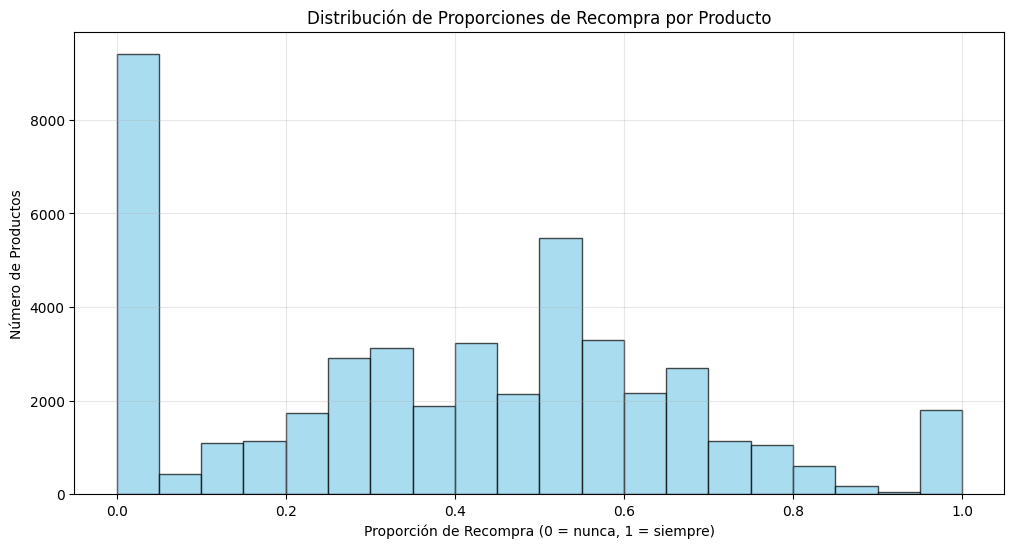

Distribución de productos por rango de recompra:


Media (40-60%)         13291
Baja (0-20%)           12842
Media-Baja (20-40%)     9758
Media-Alta (60-80%)     7304
Alta (80-100%)          2378
Name: rango_proporcion, dtype: int64

In [ ]:

# Crear histograma de las proporciones
plt.figure(figsize=(12, 6))
plt.hist(proporcion_reorden_con_nombres['proporcion'], bins=20, 
         color='skyblue', alpha=0.7, edgecolor='black')
plt.title('Distribución de Proporciones de Recompra por Producto')
plt.xlabel('Proporción de Recompra (0 = nunca, 1 = siempre)')
plt.ylabel('Número de Productos')
plt.grid(True, alpha=0.3)
plt.show()
# Crear rangos de proporciones corregido para incluir 0
proporcion_reorden_con_nombres['rango_proporcion'] = pd.cut(
    proporcion_reorden_con_nombres['proporcion'],
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], 
    include_lowest=True,
    labels=['Baja (0-20%)', 'Media-Baja (20-40%)', 'Media (40-60%)', 'Media-Alta (60-80%)', 'Alta (80-100%)'])


# Contar productos por rango
conteo_rangos = proporcion_reorden_con_nombres['rango_proporcion'].value_counts()
print("Distribución de productos por rango de recompra:")
display(conteo_rangos)

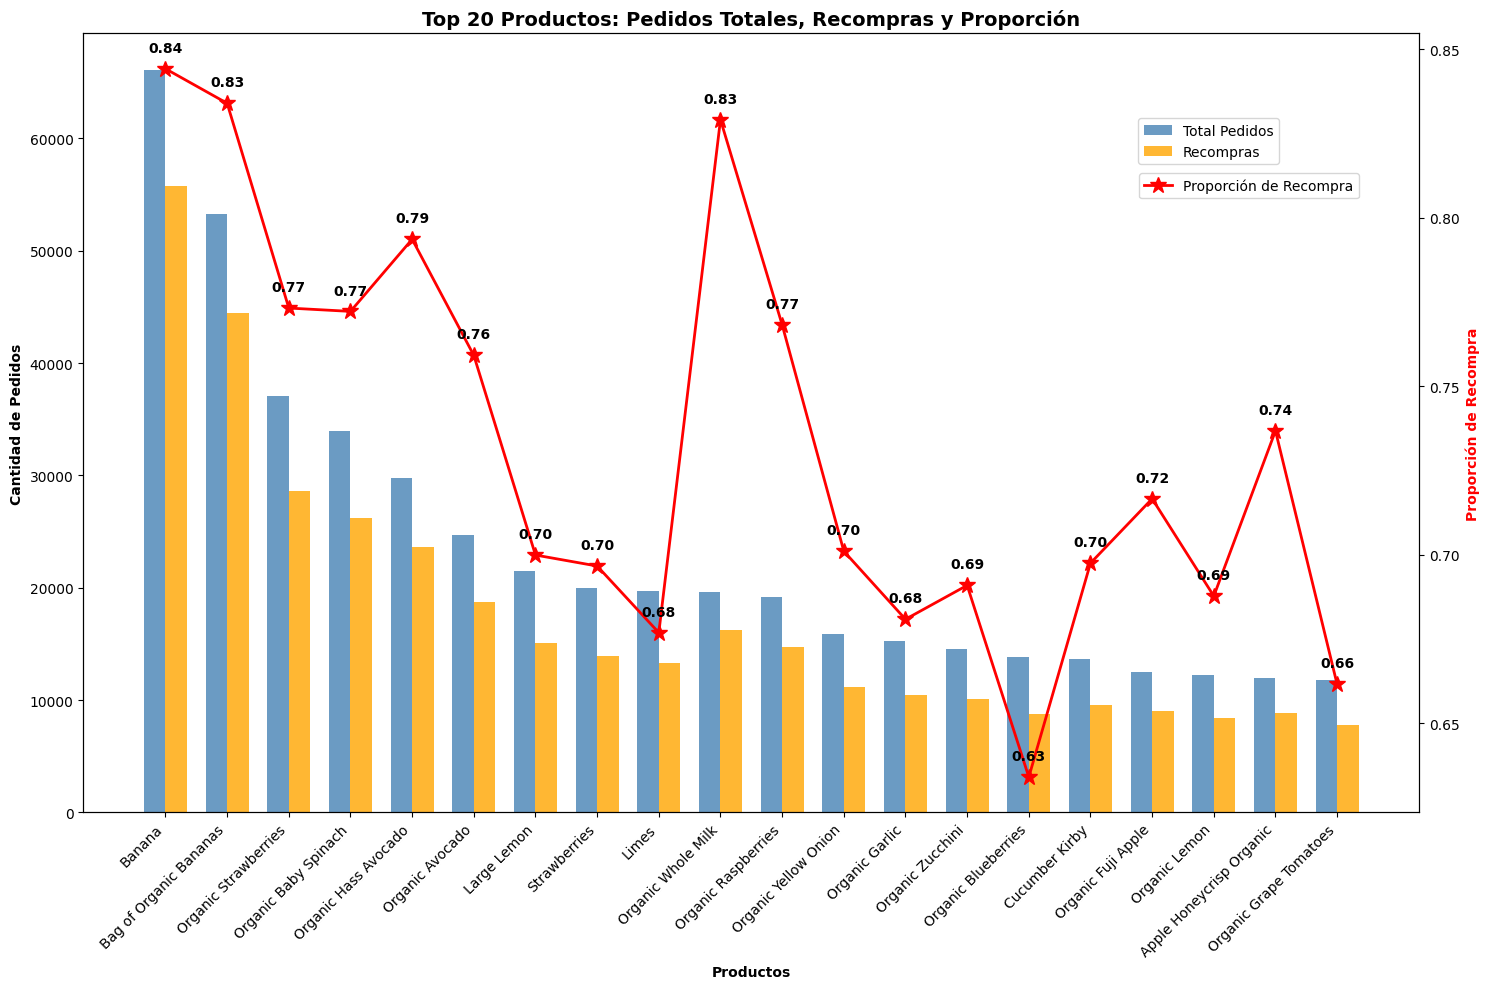

In [67]:
# Tomar los top 20 productos por volumen total 
top_20_final = proporcion_reorden_con_nombres.sort_values('total_pedidos', ascending=False).head(20)

# Crear un gráfico de barras agrupadas
fig, ax1 = plt.subplots(figsize=(15, 10))

# Configurar posiciones para las barras
x = range(len(top_20_final))
width = 0.35

# Crear barras para total de pedidos y recompras
bars1 = ax1.bar([i - width/2 for i in x], top_20_final['total_pedidos'], width, label='Total Pedidos', color='steelblue', alpha=0.8)
bars2 = ax1.bar([i + width/2 for i in x], top_20_final['recompras'], width, label='Recompras', color='orange', alpha=0.8)

# Configurar el primer eje Y (para cantidades)
ax1.set_xlabel('Productos', fontweight='bold')
ax1.set_ylabel('Cantidad de Pedidos', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(top_20_final['product_name'], rotation=45, ha='right')

# Crear segundo eje Y para las proporciones
ax2 = ax1.twinx()
line = ax2.plot(x, top_20_final['proporcion'], 'ro-', linewidth=2, marker='*', markersize=12, label='Proporción de Recompra')
ax2.set_ylabel('Proporción de Recompra', fontweight='bold', color='red')

# Leyendas y título
ax1.legend(bbox_to_anchor=(0.90, 0.9), loc='upper right')  # Leyenda de barras en el centro-derecha
ax2.legend(bbox_to_anchor=(0.96, 0.83), loc='upper right')  # Leyenda de línea más abajo
plt.title('Top 20 Productos: Pedidos Totales, Recompras y Proporción', 
          fontsize=14, fontweight='bold')

# Agregar valores en cada punto de la línea roja
for i, (x_pos, proporcion) in enumerate(zip(x, top_20_final['proporcion'])):
    ax2.annotate(f'{proporcion:.2f}', 
                xy=(x_pos, proporcion),
                xytext=(0, 10),  # 10 puntos arriba del punto
                textcoords='offset points',
                ha='center', va='bottom',
                fontsize=10, color='black', fontweight='bold')
plt.tight_layout()
plt.show()


Escribe aquí tus conclusiones
- De los 45573 productos disponibles en instacart, hay 3193 productos con un 75 a 100 % de proporcion de recompra, 5729 tienen de 0 1 25% de recompra.
- Se analizaron los 20 productos del top 20 que han sido más comprados y 19 conservaron su lugar en la lista siendo los mas comprados así como los más recomprados.
- Los productos que tienen un 100% de recompra en realidad no significa que sean los más populares de instacart ya que muchos de ellos tienen ese porcentaje porque solo se pidieron 1 vez y se volvieron a pedir otra vez. En cambio los productos del top ten, si bien no alcanzan el 100% de proporció, tampoco bajan del 60%, lo que representa que son los productos a los cuales Instacart debe su éxito.


### [C4] Para cada cliente, ¿qué proporción de sus productos ya los había pedido?

In [68]:


# Paso 1: Tabla de cantidad de pedidos por cada cliente
pedidos_por_cliente = df_orders.groupby('user_id').size().reset_index(name='total_pedidos')
display(pedidos_por_cliente.head())

clientes_2_o_mas = pedidos_por_cliente[pedidos_por_cliente['total_pedidos'] >= 2]
print(f"Clientes con 2+ pedidos: {len(clientes_2_o_mas):,}")
print(f"Esto representa el {len(clientes_2_o_mas)/len(pedidos_por_cliente)*100:.1f}% de todos los clientes")

# Obtener sus pedidos
pedidos_clientes_frecuentes = df_orders[df_orders['user_id'].isin(clientes_2_o_mas['user_id'])]

# Obtener productos de estos pedidos
productos_clientes_frecuentes = df_order_products[
    df_order_products['order_id'].isin(pedidos_clientes_frecuentes['order_id'])
]

display(pedidos_clientes_frecuentes.head())
display(productos_clientes_frecuentes.head())

# Productos más recomprados por clientes frecuentes
productos_recomprados_frecuentes = productos_clientes_frecuentes[
    productos_clientes_frecuentes['reordered'] == 1
]

# Top productos recomprados por estos clientes
top_recompras_frecuentes = productos_recomprados_frecuentes.merge(
    df_products[['product_id', 'product_name']], 
    on='product_id'
)['product_name'].value_counts().head(20)

print("Top 20 productos más recomprados por clientes frecuentes:")
display(top_recompras_frecuentes)


,user_id,total_pedidos
0,2,2
1,4,2
2,5,1
3,6,2
4,7,2


Clientes con 2+ pedidos: 102,082
Esto representa el 64.8% de todos los clientes


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,1515936,183418,11,6,13,30.0
1,1690866,163593,5,5,12,9.0
3,1768857,82516,56,0,20,10.0
5,1843871,20084,5,0,11,15.0
6,2511640,148233,40,3,8,2.0


,order_id,product_id,add_to_cart_order,reordered
0,2141543,11440,17,0
1,567889,1560,1,1
2,2261212,26683,1,1
3,491251,8670,35,1
4,2571142,1940,5,1


Top 20 productos más recomprados por clientes frecuentes:


Banana                      51526
Bag of Organic Bananas      41643
Organic Strawberries        27125
Organic Baby Spinach        24346
Organic Hass Avocado        22272
Organic Avocado             17233
Organic Whole Milk          15348
Organic Raspberries         13947
Large Lemon                 13915
Strawberries                12886
Limes                       12461
Organic Yellow Onion        10551
Organic Garlic               9800
Organic Zucchini             9471
Cucumber Kirby               8768
Organic Fuji Apple           8406
Apple Honeycrisp Organic     8367
Organic Blueberries          8213
Organic Lemon                7952
Organic Half & Half          7946
Name: product_name, dtype: int64

Clientes totales: 157,437
Clientes con 2+ pedidos: 102,082
Productos de clientes con 2+ pedidos: 4,076,632


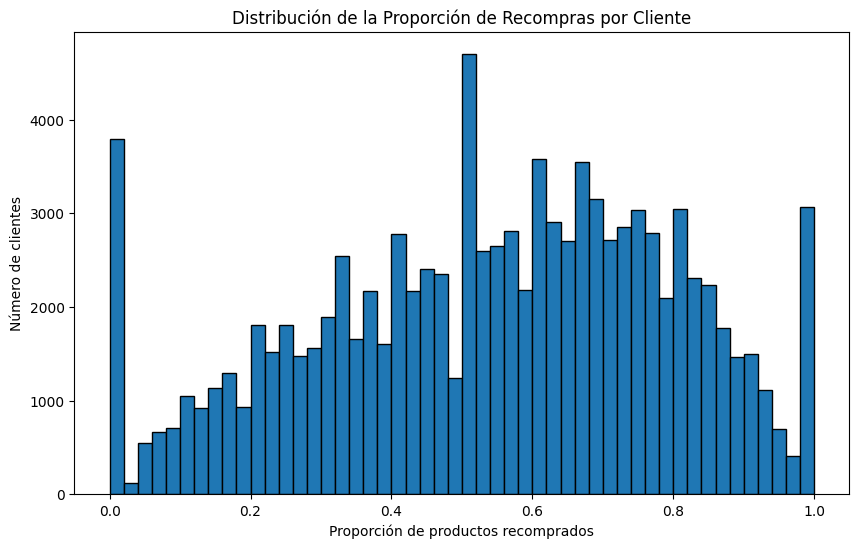

count    102082.000000
mean          0.542324
std           0.254127
min           0.000000
25%           0.360000
50%           0.566667
75%           0.740000
max           1.000000
Name: proporcion_recompras, dtype: float64
=== ANÁLISIS DETALLADO DE PROPORCIONES DE RECOMPRA POR CLIENTE ===

1. DISTRIBUCIÓN DE CLIENTES POR RANGO DE RECOMPRA:
   Media-Alta (50-75%): 35,194 clientes (34.5%)
   Media-Baja (25-50%): 27,617 clientes (27.1%)
   Alta (75-100%): 23,217 clientes (22.7%)
   Baja (0-25%): 16,054 clientes (15.7%)

2. ANÁLISIS DE CLIENTES EXTREMOS:
   Clientes que NUNCA recompran (0%): 3,786
   Clientes que SIEMPRE recompran (100%): 3,010

3. CORRELACIÓN:
   Entre total de productos y proporción de recompra: 0.288

4. PROPORCIÓN DE RECOMPRA POR TIPO DE COMPRADOR:
   Comprador Ligero (1-10): 0.489 promedio de recompra
   Comprador Moderado (11-50): 0.506 promedio de recompra
   Comprador Frecuente (51-100): 0.632 promedio de recompra
   Comprador Intensivo (100+): 0.727 promedio d

In [69]:
# Hacer merge para obtener user_id
df_order_products_con_user = df_order_products.merge(df_orders[['order_id', 'user_id']], on='order_id', how='left')

#  Filtrar solo clientes con 2+ pedidos
pedidos_por_cliente = df_orders.groupby('user_id').size()
clientes_2_o_mas = pedidos_por_cliente[pedidos_por_cliente >= 2].index

# Filtrar el DataFrame para incluir solo estos clientes
df_order_products_filtrado = df_order_products_con_user[
    df_order_products_con_user['user_id'].isin(clientes_2_o_mas)
]

print(f"Clientes totales: {df_orders['user_id'].nunique():,}")
print(f"Clientes con 2+ pedidos: {len(clientes_2_o_mas):,}")
print(f"Productos de clientes con 2+ pedidos: {len(df_order_products_filtrado):,}")
# Calcular para cada cliente sus productos totales y recomprados
cliente_recompras = df_order_products_filtrado.groupby('user_id').agg({
    'product_id': 'count','reordered': 'sum'}).rename(columns={'product_id': 'total_productos','reordered': 'productos_recomprados'})

# Calcular la proporción de recompras por cliente
cliente_recompras['proporcion_recompras'] = (cliente_recompras['productos_recomprados'] / cliente_recompras['total_productos'])

# Crear el gráfico de distribución
plt.figure(figsize=(10, 6))
plt.hist(cliente_recompras['proporcion_recompras'], bins=50, edgecolor='black')
plt.title('Distribución de la Proporción de Recompras por Cliente')
plt.xlabel('Proporción de productos recomprados')
plt.ylabel('Número de clientes')
plt.show()

# Mostrar estadísticas
print(cliente_recompras['proporcion_recompras'].describe())
print("=== ANÁLISIS DETALLADO DE PROPORCIONES DE RECOMPRA POR CLIENTE ===")

#1. Estadísticas por rangos de proporción

cliente_recompras['rango_proporcion'] = pd.cut(cliente_recompras['proporcion_recompras'], 
                                               bins=[0, 0.25, 0.5, 0.75, 1.0], 
                                               include_lowest=True,

labels=['Baja (0-25%)', 'Media-Baja (25-50%)', 'Media-Alta (50-75%)', 'Alta (75-100%)'])


conteo_rangos = cliente_recompras['rango_proporcion'].value_counts()
print("\n1. DISTRIBUCIÓN DE CLIENTES POR RANGO DE RECOMPRA:")
for rango, cantidad in conteo_rangos.items():
    porcentaje = (cantidad / len(cliente_recompras)) * 100
    print(f"   {rango}: {cantidad:,} clientes ({porcentaje:.1f}%)")

# 2.Análisis de clientes extremos
print("\n2. ANÁLISIS DE CLIENTES EXTREMOS:")
clientes_sin_recompras = cliente_recompras[cliente_recompras['proporcion_recompras'] == 0]
clientes_solo_recompras = cliente_recompras[cliente_recompras['proporcion_recompras'] == 1]

print(f"   Clientes que NUNCA recompran (0%): {len(clientes_sin_recompras):,}")
print(f"   Clientes que SIEMPRE recompran (100%): {len(clientes_solo_recompras):,}")

#3. Correlación entre número de productos y proporción de recompra
correlacion = cliente_recompras['total_productos'].corr(cliente_recompras['proporcion_recompras'])
print(f"\n3. CORRELACIÓN:")
print(f"   Entre total de productos y proporción de recompra: {correlacion:.3f}")

# 4. Análisis por volumen de compra
cliente_recompras['categoria_comprador'] = pd.cut(cliente_recompras['total_productos'],
    bins=[0, 10, 50, 100, float('inf')],labels=['Comprador Ligero (1-10)', 'Comprador Moderado (11-50)', 'Comprador Frecuente (51-100)', 'Comprador Intensivo (100+)'])

print("\n4. PROPORCIÓN DE RECOMPRA POR TIPO DE COMPRADOR:")
for categoria in cliente_recompras['categoria_comprador'].cat.categories:
    subset = cliente_recompras[cliente_recompras['categoria_comprador'] == categoria]
    if len(subset) > 0:
        promedio = subset['proporcion_recompras'].mean()
        print(f"   {categoria}: {promedio:.3f} promedio de recompra")

Escribe aquí tus conclusiones
- Únicamente se tomaron en cuenta para éste análisis a los clientes que tienen registro de 2 o más pedidos (102,082), porque son los clientes que podrían mostrar patrones de recompra. Por esta razon se descartaron 55,357 clientes que solo hicieron un pedido.
- En promedio, se tiene una proporción de recompras por cliente del 54.23 %, lo que indica que poco más de la mitad de los productos que compran los clientes son recompras.
- 3,786 clientes nunca recompran
- 3,010 siempre recompraron
- Exciste una correlación del .288 entre el total de productos y la proporción de recompra. Lo que significa que existe una tendendia pero no muy fuerte a recomprar.

### [C5] ¿Cuáles son los 20 principales artículos que las personas ponen primero en sus carritos?

In [70]:
#preparar datos
# Filtrar solo productos que fueron el primer item añadido al carrito
first_items = df_order_products[df_order_products['add_to_cart_order'] == 1]
display(first_items.head())
# Contar cuántas veces cada producto fue añadido primero
first_items_count = first_items['product_id'].value_counts().head(20)
display(first_items_count)

,order_id,product_id,add_to_cart_order,reordered
1,567889,1560,1,1
2,2261212,26683,1,1
14,1961225,37553,1,1
16,639939,10017,1,1
23,750040,8518,1,0


24852    15562
13176    11026
27845     4363
21137     3946
47209     3390
21903     3336
47766     3044
19660     2336
16797     2308
27966     2024
44632     1914
49235     1797
47626     1737
196       1733
38689     1397
26209     1370
12341     1340
5785      1310
27086     1309
22935     1246
Name: product_id, dtype: int64

In [71]:
# Convertir a DataFrame y hacer merge
top_20_first = pd.DataFrame({
    'product_id': first_items_count.index,'veces_primero': first_items_count.values})
# Merge con products
result = top_20_first.merge(df_products[['product_id', 'product_name']], 
                           on='product_id', how='left')
display(result)

,product_id,veces_primero,product_name
0,24852,15562,Banana
1,13176,11026,Bag of Organic Bananas
2,27845,4363,Organic Whole Milk
3,21137,3946,Organic Strawberries
4,47209,3390,Organic Hass Avocado
5,21903,3336,Organic Baby Spinach
6,47766,3044,Organic Avocado
7,19660,2336,Spring Water
8,16797,2308,Strawberries
9,27966,2024,Organic Raspberries


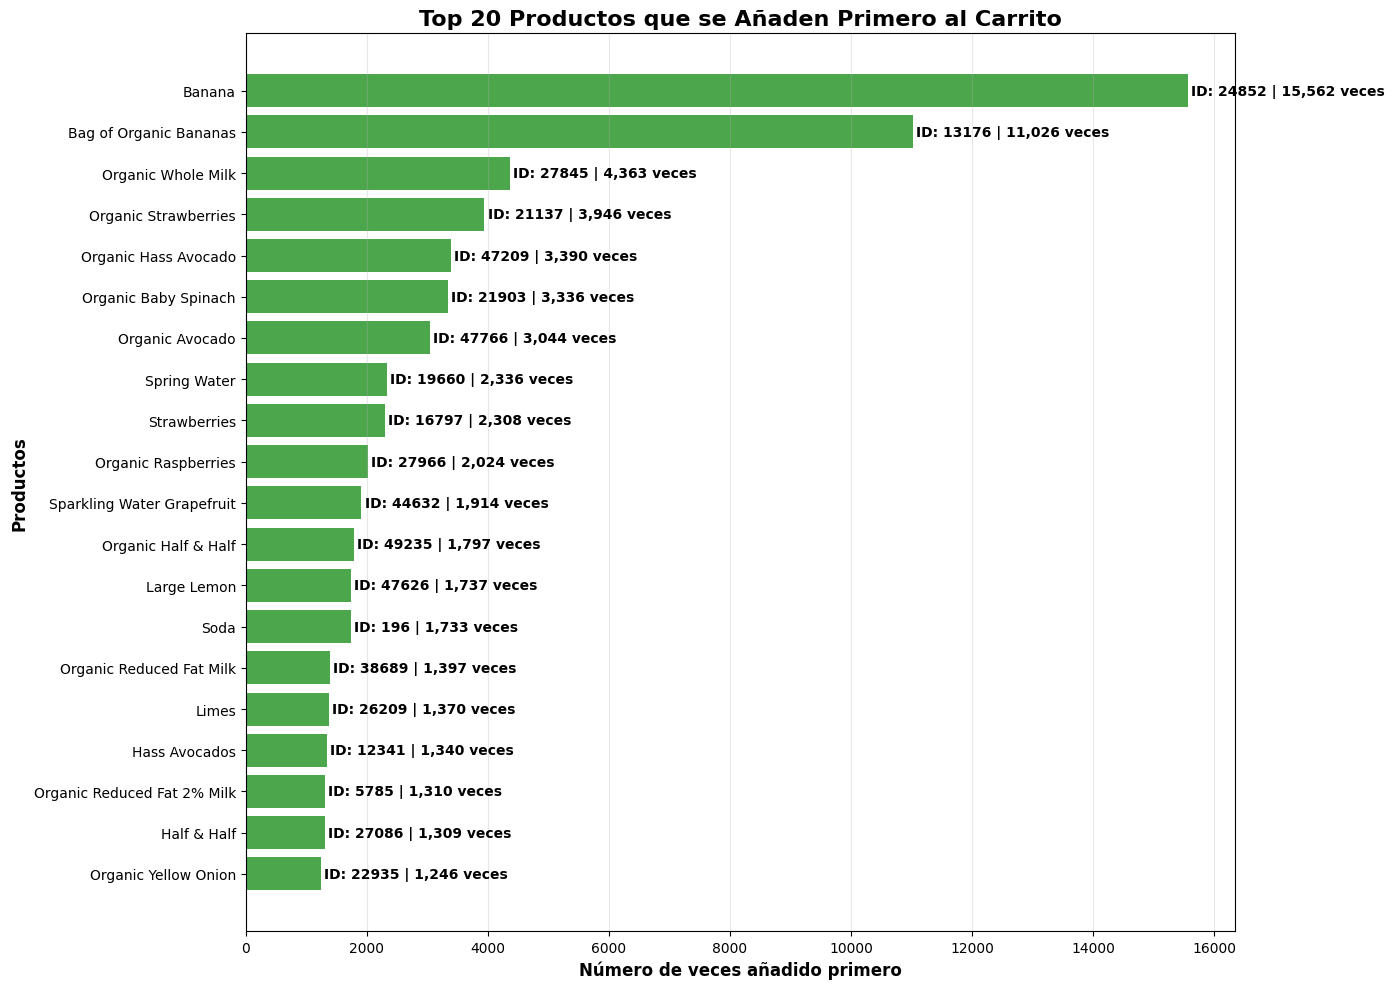

In [72]:
# Crear gráfico de barras horizontales para mejor visualización
plt.figure(figsize=(14, 10))

# Crear las barras
bars = plt.barh(range(len(result)), result['veces_primero'], color='green', alpha=0.7)

# Configurar etiquetas del eje Y con nombres de productos
plt.yticks(range(len(result)), result['product_name'])

# Agregar anotaciones en cada barra con ID y cantidad
for i, (product_id, veces, bar) in enumerate(zip(result['product_id'], result['veces_primero'], bars)):
    plt.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2,
             f'ID: {product_id} | {veces:,} veces',
             va='center', ha='left', fontweight='bold', fontsize=10)

plt.title('Top 20 Productos que se Añaden Primero al Carrito', fontsize=16, fontweight='bold')
plt.xlabel('Número de veces añadido primero', fontsize=12, fontweight='bold')
plt.ylabel('Productos', fontsize=12, fontweight='bold')
plt.gca().invert_yaxis()  # Para mostrar el #1 arriba
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()


In [73]:
#celda adicional para comparar con analisis de productos top 20  mas populares
top_20_mas_comprados = df_order_products['product_id'].value_counts().head(20)
top_20_mas_comprados_df = pd.DataFrame({'product_id': top_20_mas_comprados.index,'total_compras': top_20_mas_comprados.values})

# Hacer merge con nombres
top_20_mas_comprados_con_nombres = top_20_mas_comprados_df.merge(df_products[['product_id', 'product_name']], on='product_id', how='left')

# Comparar las dos listas
productos_primero = set(result['product_id'])
productos_mas_comprados = set(top_20_mas_comprados_con_nombres['product_id'])

# Identificar productos que están en ambas listas
productos_en_ambas = productos_primero.intersection(productos_mas_comprados)
productos_solo_primero = productos_primero - productos_mas_comprados
productos_solo_mas_comprados = productos_mas_comprados - productos_primero

print("=== ANÁLISIS COMPARATIVO ===")
print(f"Productos en ambas listas: {len(productos_en_ambas)}")
print(f"Productos solo en 'primero en carrito': {len(productos_solo_primero)}")
print(f"Productos solo en 'más comprados': {len(productos_solo_mas_comprados)}")

print("\n=== PRODUCTOS QUE APARECEN EN AMBAS LISTAS ===")
productos_comunes = df_products[df_products['product_id'].isin(productos_en_ambas)]
for i, row in productos_comunes.iterrows():
    print(f"• {row['product_name']} (ID: {row['product_id']})")

print("\n=== PRODUCTOS SOLO EN 'PRIMERO EN CARRITO' ===")
productos_solo_primero_nombres = df_products[df_products['product_id'].isin(productos_solo_primero)]
for i, row in productos_solo_primero_nombres.iterrows():
    print(f"• {row['product_name']} (ID: {row['product_id']})")

print("\n=== PRODUCTOS SOLO EN 'MÁS COMPRADOS' ===")
productos_solo_comprados_nombres = df_products[df_products['product_id'].isin(productos_solo_mas_comprados)]
for i, row in productos_solo_comprados_nombres.iterrows():
    print(f"• {row['product_name']} (ID: {row['product_id']})")

=== ANÁLISIS COMPARATIVO ===
Productos en ambas listas: 12
Productos solo en 'primero en carrito': 8
Productos solo en 'más comprados': 8

=== PRODUCTOS QUE APARECEN EN AMBAS LISTAS ===
• Bag of Organic Bananas (ID: 13176)
• Strawberries (ID: 16797)
• Organic Strawberries (ID: 21137)
• Organic Baby Spinach (ID: 21903)
• Organic Yellow Onion (ID: 22935)
• Banana (ID: 24852)
• Limes (ID: 26209)
• Organic Whole Milk (ID: 27845)
• Organic Raspberries (ID: 27966)
• Organic Hass Avocado (ID: 47209)
• Large Lemon (ID: 47626)
• Organic Avocado (ID: 47766)

=== PRODUCTOS SOLO EN 'PRIMERO EN CARRITO' ===
• Soda (ID: 196)
• Organic Reduced Fat 2% Milk (ID: 5785)
• Hass Avocados (ID: 12341)
• Spring Water (ID: 19660)
• Half & Half (ID: 27086)
• Organic Reduced Fat Milk (ID: 38689)
• Sparkling Water Grapefruit (ID: 44632)
• Organic Half & Half (ID: 49235)

=== PRODUCTOS SOLO EN 'MÁS COMPRADOS' ===
• Organic Lemon (ID: 5876)
• Apple Honeycrisp Organic (ID: 8277)
• Organic Garlic (ID: 24964)
• Organi


Escribe aquí tus conclusiones
- Se observa que 12 de los 20 productos más polulares por número de compras, también son los primeros en agregarse al carrito, encabezando el listado las bananas y las bolsas de bananas.
- Los 8 productos que no aparecen en la lista de 20 productos mas populares, pero si están como primer articulo añadido al carrito son en su mayoría bebidas, a excepción de los aguacates Hass.


### Conclusion general del proyecto:

Llevar a cabo este proyecto en su totalidad fue un trabajo bastante retador pero que en general me gustó realizar. No tenía noción de toda la versatilidad de herramientas que tiene phyton y que se podían hacer tantas cosas. Fue bastante satisfactorio poner en práctica real toda la teoría que estudié previamente en los sprints anteriores. 



### Conclusiones finales del proyecto:

RESUMEN DE LOS HALLAZGOS PRINCIPALES:
1. COMPORTAMIENTO DEL CLIENTE:
   - Horarios pico: 10:00 - 16:00 hrs
   - Días preferidos: Domingos y lunes
   - Frecuencia de compra: Promedio de 11 días entre pedidos
   - Tamaño del carrito: Promedio de 10 productos por pedido.
2. LEALTAD DEL CLIENTE:
   - 64.8% de los clientes hicieron más de una compra en una proporción de recompra del 49.5%.
3. PRODUCTOS FAVORITOS:
   - Bananas!!! encabezaron los top 20 en todos los análisis de pedidos y productos.
   - Productos frescos como frutas, vegetales y lácteos lideran las preferencias.
   - 
RECOMENDACIONES ESTRATÉGICAS PARA EL NEGOCIO
1. Buena gestión de Inventario para asegurar stock abundante de bananas, fresas y productos orgánicos durante horas pico.
2. Excelente logísitica de entrega para reforzar la capacidad de entrega los domingos y lunes.
3. Reforzar estrategias de Marketing mediante programas de fidelización para clientes frecuentes así como propmociones especiales si los clientes acumulan cierto número de pedidos.
4. Mejorar la experiencia al usuario mediante la sugerencia de productos basados en las recompras por cada cliente o crear listas de compra inteligentes.
5. Destacar productos más populares en la primera interacción con la aplicación al momendto de iniciarla.
6. Crear una estrategia de retencio a los clientes de una sola compra mediante envío de emails con descuentos especiales si regresan a hacer otra compra.
7. Dar privilegios a clientes frecuentes como entregas prioritarias y acceso anticipado a los productos nuevos.
8. Fortalecer los productos de categorías exitosas mediante la amplicación de la variedad de presentaciones por ejemplo vender por pieza, por bolsa chica, mediana grande y jumbo a mejor precio respectivamente.
9. Desarrollar linea de productos de marca propia en las categorías más populares.